<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QCNN_RobustnessVerification_Guan2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Verifying the robustness of quantum classifiers (fidelity bound, SDP, QCQP): Guan, Fang and Ying (2021) step by step

**Paper.** Ji Guan, Wang Fang and Mingsheng Ying, *Robustness Verification of Quantum Classifiers*, in: Computer Aided Verification (CAV 2021), Lecture Notes in Computer Science 12759, Springer, 2021, DOI [10.1007/978-3-030-81685-8_7](https://doi.org/10.1007/978-3-030-81685-8_7), arXiv:2008.07230 [quant-ph].

**What this notebook does.** A quantum classifier is a quantum channel `E` followed by a measurement `{M_k}`. The paper asks: for a training state `rho`, how far (in *fidelity distance* `1 - F`) can the state move before the predicted class changes? It derives (i) a cheap **analytic robust bound** from the output probabilities alone (Lemma 1), (ii) the **optimal bound** as a semidefinite program (Theorem 2), (iii) a pure-state version as a quadratically constrained program (Corollary 1), and three algorithms that compute the **robust accuracy** of a classifier and return **adversarial examples**. The notebook

1. implements Lemma 1, Theorem 2, Corollary 1 and Algorithms 1 to 3 from scratch (no SDP package is available, so the SDP is solved **exactly** through its one-dimensional Lagrange dual and the QCQP through an exact trust-region solver; both are cross-checked against each other and against brute force),
2. re-creates the paper's four experiments with their data recipes: single-qubit state classification, 6-qubit quantum phase recognition (QCNN on SPT ground states), 6-qubit cluster-excitation detection (TensorFlow-Quantum style QCNN) and MNIST 3-versus-6 with amplitude encoding on 8 qubits,
3. trains the four classifiers, draws and executes every circuit with Qiskit, verifies robustness with the paper's algorithms at the paper's four `eps` values for each task and compares the numbers with Tables 1 to 4,
4. attacks the classifiers with gradient attacks (the verified radius must never be beaten) and re-executes every adversarial example on the Qiskit circuits,
5. adds a classical baseline on identical inputs and ends with one verdict per claim of the paper.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. The committed outputs were produced with `FAST_MODE = False` (three complete pipelines with seeds 42, 43, 44 and the longer training budgets listed in the configuration cell; about 33 minutes on an 8-thread CPU). Set `FAST_MODE = True` for one seed and shortened training (about 9 minutes). No GPU, no IBM account and no private data are needed; MNIST is downloaded from the public Hugging Face mirror `ylecun/mnist`.

**What you get at the end.** Tables 1 to 4 of the paper next to the notebook's numbers, a figure of the certified robust accuracy against `eps`, executed adversarial examples (also the MNIST images of the paper's Fig. 3), and an honest list of what was and was not reproduced. One finding goes beyond the paper: for a unitary circuit with a projective measurement and a pure input the paper's analytic bound (Lemma 1) is already *optimal*, which the notebook proves in two lines and confirms numerically.

## The paper in one page

**Setting.** A quantum classifier `A = (E, {M_k})` outputs `A(rho) = argmax_k tr(M_k^† M_k E(rho))`. The distance between states is the fidelity distance `D(rho, sigma) = 1 - F(rho, sigma)` with `F = (tr sqrt(sqrt(rho) sigma sqrt(rho)))^2`. A state `sigma` with `D(rho, sigma) <= eps` and a different class is an **eps-adversarial example**; `rho` is **eps-robust** if there is none. The **robust accuracy** is the share of eps-robust states in the training set (Definition 4; Section 4 says that only correctly classified states are considered).

**The results.**

* **Lemma 1 (robust bound).** With `p1 >= p2` the two largest outcome probabilities of `E(rho)`: if `sqrt(p1) - sqrt(p2) > sqrt(2 eps)` then `rho` is eps-robust. It needs only the measurement statistics (cost `O(|C| n^3)`).
* **Theorem 1 / Theorem 2 (optimal bound).** `delta_k = min 1 - F(rho, sigma)` subject to `sigma >= 0`, `tr sigma = 1`, `tr[(M_l^† M_l - M_k^† M_k) E(sigma)] <= 0` is a **semidefinite program**; `delta = min_{k != l} delta_k` is the optimal robust bound and `rho` is eps-robust iff `eps <= delta`.
* **Corollary 1.** For adversarial examples restricted to *pure* states the same optimisation is a (non-convex) **QCQP**.
* **Algorithm 1** (one state: SDP for every wrong class), **Algorithm 2** (a training set: Lemma 1 prunes, Algorithm 1 decides the rest, returns the adversarial examples), **Algorithm 3** (only Lemma 1, an under-approximation of the robust accuracy).

**Experiments (Section 7), all implemented in TensorFlow Quantum with CVXPY as SDP solver.**

| # | Task | Data | Classifier | Reported accuracy |
|---|---|---|---|---|
| 7.1 | quantum bits classification | 2 Bloch vectors at polar angles 1 and 1.23, 800 train / 200 validation | `Ry(theta)` and a Z measurement, learned `theta = 0.4835` | 100% / 100% |
| 7.2 | quantum phase recognition | ground states of the 6-spin Z2xZ2 SPT Hamiltonian, 1000 train (line `h2/J = 0`) / 400 validation (two rectangles) | QCNN (114 parameters), measurement `{|+>, |->}` | 97.7% / 95.25% |
| 7.3 | cluster excitation detection | 6-qubit cluster state with `Rx(theta)` on one qubit, `theta` in `[-pi, pi]`, 840 / 360 | QCNN of TensorFlow Quantum, measurement `{|0>, |1>}` | 99.76% / 99.44% |
| 7.4 | MNIST 3 versus 6 | 700 + 700 images, 16 x 16 pixels, amplitude encoding on 8 qubits, 1000 / 400 | QCNN, measurement `{|+>, |->}` | 98.4% / 97.5% |

All four use Adam on the mean squared error of Eq. (8). **Robustness results (Tables 1 to 4):** for four values of `eps` per task (`1e-3 ... 4e-3` for the single qubit, `1e-4 ... 4e-4` for the others) the robust accuracy computed with Lemma 1 (Algorithm 3) and with the optimal bound (Algorithm 2) and the verification times: e.g. single qubit `88.13 / 75.88 / 58.88 / 38.25 %` (Lemma 1) against `90.00 / 76.50 / 59.75 / 38.88 %` (Algorithm 2), QPR `99.2 ... 98.3 %`, cluster `99.05 ... 97.86 %` against `100 %`, MNIST `99.7 ... 99.2 %`. Algorithm 3 takes seconds or less, Algorithm 2 up to 365 s. Fig. 3 shows two MNIST images and their adversarial images found by the QCQP.

## What follows the paper and what had to be chosen

The paper reports its results but, for the circuits and the data recipes, points to figures and to the extended version; several items are not stated. Everything that is not in the paper is chosen below and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Robust bound, optimal bound, algorithms | Lemma 1, Theorems 1 and 2, Corollary 1, Algorithms 1 to 3 | implemented as stated. **Solver:** the paper calls CVXPY (SDP) and SciPy (QCQP). Here no SDP package is available, so (a) for a pure input the SDP has a *linear* objective `<psi|sigma|psi>` and a single linear constraint, which is solved **exactly** through its Lagrange dual (one-dimensional, secular equation), and (b) the pure-state QCQP is solved exactly as a trust-region problem. Both agree to about `1e-15`; a brute-force Bloch-sphere search confirms the single-qubit case |
| Robust accuracy | proportion of eps-robust states in the training set; Section 4: only correctly classified states count | Algorithm 2 is run **literally as written** (this is what the paper's tables contain) *and* the Section 4 definition (correctly classified states only) is reported next to it |
| Qubit data (7.1) | 2 Bloch vectors at polar angles 1 and 1.23 in the X-Z plane, "randomly sample" around them, 800 / 200 | the TensorFlow Quantum recipe: polar offset and azimuthal tilt uniform in `[-b, b]`, `b = |1.23 - 1| / 5`; 800 / 200; classifier `Ry(theta)` + Z measurement |
| QPR data (7.2) | ground states of the open 6-spin chain, `h2/J = 0`, `h1/J` uniform in `[0, 1.2]`, 1000 train; 400 validation in two rectangles of the `(h1/J, h2/J)` plane (rectangle coordinates not given), exact phase boundary from a numerical simulation | exact diagonalisation (real symmetric 64 x 64). Train labels: SPT iff `h1/J < 1` (self-dual critical point). **Validation rectangles chosen by us**; their labels come from the string order parameter `min(|<Z0 X1 X3 Z4>|, |<Z1 X2 X4 Z5>|)` thresholded at its value at the exactly known critical point `(1, 0)`. `h1/J` starts at 0.0012 because at exactly 0 the ground state is four-fold degenerate; the arbitrary global sign of every eigenvector is fixed so that its overlap with `|+>^6` is positive (irrelevant for the circuits, relevant for PCA plots and classical baselines) |
| QPR circuit (7.2) | QCNN of Fig. 4b, unitaries `exp(-i sum theta_j Lambda_j)` in a generalised Gell-Mann basis, **114 parameters**, measurement `{|+>, |->}` | conv `U1` (even bonds), `U2` (odd bonds), measurement-controlled pooling `V1`, conv `U3`, pooling `V2`, fully connected `F`; `Lambda_j` = the 15 two-qubit Pauli strings (also a basis of su(4)); parameters shared within a layer = **66 parameters**. The 114 of the paper cannot be reconstructed from the text |
| Cluster data (7.3) | cluster-state circuit + `Rx(theta)` on one qubit, `theta` in `[-pi, pi]`, label 1 iff `|theta| <= pi/2`, 840 / 360 | `H` on 6 qubits, `CZ` ring, `Rx(theta)` on qubit 2 (the qubit is not stated) |
| Cluster / MNIST circuit | TensorFlow Quantum QCNN (Fig. 5b and 6): `two_qubit_unitary` (15 parameters) conv layers, `two_qubit_pool` (6 parameters) pooling layers | the same gate set of the TFQ tutorial, 3 conv + 3 pooling layers with weight sharing, **63 parameters**, 6 and 8 qubits; the layer widths of the figures are not recoverable and follow the TFQ halving scheme |
| MNIST data (7.4) | 700 images of 3, 700 of 6, 16 x 16 pixels (the text also mentions 24 x 24, which cannot be 8 qubits), amplitude encoding, 1000 / 400 | MNIST train images, bilinear resize 28 -> 16, amplitude encoding of the 256 pixel intensities; random 1000 / 400 stratified split |
| Training | Adam, MSE of Eq. (8); learning rate, epochs, initialisation not given | full-batch Adam, cosine learning-rate decay, a few random restarts (lowest final training loss kept), **class-balanced weights** in the MSE (matters only for QPR where 83% of the training line is one class); budgets in the configuration cell |
| Verification hardware | Intel i7-9700, CVXPY | whatever machine runs the notebook; absolute times cannot be compared |

In [1]:
# Install (Colab or a fresh local environment). Pinned to the versions this notebook was tested with.
# Colab already ships numpy, scipy, pandas, scikit-learn, matplotlib, torch and pillow.
# If pip reports that a package was upgraded, restart the runtime once and run all cells again.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("qiskit", "pylatexenc", "torch", "huggingface_hub", "pyarrow"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc", "huggingface_hub", "pyarrow"], check=False)
    print("install finished; if the next cell fails to import qiskit, restart the runtime and run all again")
else:
    print("all required packages are already available; nothing to install")

all required packages are already available; nothing to install


In [2]:
# Configuration: every tunable constant lives here.
import time
T0 = time.time()                       # wall-clock start of the run
SEED = 42                              # global seed
FAST_MODE = False                       # True: a few minutes, one seed; False: more training, three seeds, more attacks
DATA_DIR = "qc335_data"                # downloads are cached here (MNIST parquet, ~20 MB)
IBM_TOKEN = ""                         # not used: every circuit is simulated exactly (no hardware in this paper)

# --- the four experiments of the paper (sample sizes as in Sections 7.1 to 7.4) ---
N_QUBITS_TASK = {"qubit": 1, "qpr": 6, "cluster": 6, "mnist": 8}
SPLIT = {"qubit": (800, 200), "qpr": (1000, 400), "cluster": (840, 360), "mnist": (1000, 400)}   # (train, validation)
# the four fidelity thresholds eps of Tables 1 to 4
EPS = {"qubit":   [1e-3, 2e-3, 3e-3, 4e-3],
       "qpr":     [1e-4, 2e-4, 3e-4, 4e-4],
       "cluster": [1e-4, 2e-4, 3e-4, 4e-4],
       "mnist":   [1e-4, 2e-4, 3e-4, 4e-4]}

# --- training (Adam on the MSE of Eq. 8, full batch) ---
LR = {"qubit": 0.05, "qpr": 0.05, "cluster": 0.03, "mnist": 0.1}   # CHOICE: the paper only says "Adam"
INIT_SCALE = {"qubit": 0.5, "qpr": 0.3, "cluster": 0.5, "mnist": 0.5}   # CHOICE: N(0, scale^2) initial parameters

if FAST_MODE:
    SEEDS = [SEED]                                        # one full pipeline
    EPOCHS = {"qubit": 150, "qpr": 300, "cluster": 250, "mnist": 120}
    RESTARTS = {"qubit": 2, "qpr": 2, "cluster": 2, "mnist": 1}      # random restarts per task, best training loss kept
    N_ATTACK = 24                                         # states used for the gradient-attack tightness study
    N_CROSSCHECK = 30                                     # states used for the independent exact solvers
    N_EXECUTE = 20                                        # adversarial examples re-executed through the Qiskit circuits
else:
    SEEDS = [SEED, SEED + 1, SEED + 2]                    # three complete pipelines (data, training, verification)
    EPOCHS = {"qubit": 300, "qpr": 600, "cluster": 500, "mnist": 250}
    RESTARTS = {"qubit": 3, "qpr": 3, "cluster": 2, "mnist": 2}
    N_ATTACK = 60
    N_CROSSCHECK = 60
    N_EXECUTE = 40

TOL_PTS = 2.0                          # verdict tolerance for percentages (points)
TOL_ABS = 0.02                         # verdict tolerance for plain numbers (e.g. the learned angle)
print(f"FAST_MODE={FAST_MODE}  seeds={SEEDS}  epochs={EPOCHS}")

FAST_MODE=False  seeds=[42, 43, 44]  epochs={'qubit': 300, 'qpr': 600, 'cluster': 500, 'mnist': 250}


In [3]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, "1")      # one BLAS thread: shared CPU and a reproducible summation order
import sys, io, math, json, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import brentq
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import torch
torch.set_num_threads(1)
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator, Statevector

warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DATA = Path(DATA_DIR); DATA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
PI = math.pi
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2


In [4]:
# The paper's reported numbers (Section 7 and Tables 1 to 4), used for the comparison at the end and for the diagnostics.
PAPER = {
    "qubit":   dict(theta=0.4835, train=100.0, val=100.0, lemma=[88.13, 75.88, 58.88, 38.25], alg2=[90.00, 76.50, 59.75, 38.88],
                    t3=[0.0050, 0.0048, 0.0047, 0.0048], t2=[1.3260, 2.7071, 4.6285, 6.9095], left=95, nonrobust=80),
    "qpr":     dict(train=97.7, val=95.25, lemma=[99.20, 98.80, 98.60, 98.30], alg2=[99.20, 98.80, 98.60, 98.40],
                    t3=[1.4892, 1.4850, 1.4644, 1.4789], t2=[19.531, 25.648, 28.738, 33.537]),
    "cluster": dict(train=99.76, val=99.44, lemma=[99.05, 98.81, 98.21, 97.86], alg2=[100.0, 100.0, 100.0, 100.0],
                    t3=[1.2899, 1.2794, 1.2544, 1.2567], t2=[209.52, 244.79, 325.97, 365.30]),
    "mnist":   dict(train=98.4, val=97.5, lemma=[99.70, 99.40, 99.30, 99.20], alg2=[99.80, 99.60, 99.30, 99.30],
                    t3=[0.0803, 0.1315, 0.0775, 0.0811], t2=[0.3955, 0.6751, 0.7653, 0.8855]),
}

## Part 1. The theory as code: Lemma 1, Theorem 2, Corollary 1, Algorithms 1 to 3

**Heisenberg picture.** Write `A_k = E^†(M_k^† M_k)`. Then `sum_k A_k = I` and `p_k(rho) = tr(A_k rho)`. For a pure input `|psi>`, `p_k = <psi|A_k|psi>`. The classifier predicts `argmax_k p_k`.

**Lemma 1** certifies robustness when `sqrt(p1) - sqrt(p2) > sqrt(2 eps)`, i.e. the state is certified up to the radius `margin^2 / 2` with `margin = sqrt(p1) - sqrt(p2)`.

**Theorem 2 for a pure input, solved exactly.** For `rho = |psi><psi|` the fidelity is `F(rho, sigma) = <psi|sigma|psi>`, **linear** in `sigma`. With `W = A_l - A_k` the SDP of Theorem 2 is
`max <psi|sigma|psi>` subject to `sigma >= 0`, `tr sigma = 1`, `tr(W sigma) <= 0`, and `delta_k = 1 - max F`. It has one linear constraint, so strong duality gives
`max F = min_{lam >= 0} lambda_max(|psi><psi| - lam W)`.
Any `lam >= 0` is a valid **certificate** (weak duality: `delta_k >= 1 - lambda_max(...)`). The function of `lam` is convex, and `lambda_max` of "diagonal plus rank one" is the largest root of a secular equation, so each evaluation costs `O(n)` after one eigendecomposition of `W`. The class `DualSDP` below bisects on the sign of the derivative. At the optimum the top eigenvector is a pure state exactly on the decision boundary (`tr(W sigma) = 0`): the adversarial example of Algorithm 1.

**Corollary 1 (pure adversarial examples), solved exactly.** Any pure `|u>` with `F(psi, u) = 1 - eps` is `sqrt(1-eps)|psi> + sqrt(eps)|phi>` with `phi` a unit vector orthogonal to `psi`. Minimising `<u|W|u>` over `phi` is a trust-region sub-problem with an exact solution (secular equation). The radius is the first `eps` at which the minimum reaches 0; this is the QCQP of Corollary 1, and the same routine returns the **worst-case state at any given eps**. Because the joint numerical range of two Hermitian matrices is convex, the pure-state QCQP and the mixed-state SDP have the same optimum when `rho` is pure. The notebook checks this to machine precision.

**Beyond the paper: when is Lemma 1 tight?** If `E` is unitary and the measurement projective, `W = Pi_l - Pi_k` has eigenvalues `+1, -1, 0` and, with `p_l = <psi|Pi_l|psi>`, the best state with `p_l <= p_k` maximises `sqrt(p_l q_l) + sqrt(p_k q_k) + sqrt(p_r q_r)` under `q_l <= q_k`; by Cauchy-Schwarz the optimum is `F = 1 - (sqrt(p_l) - sqrt(p_k))^2 / 2`, **exactly the bound of Lemma 1**. All four experiments of the paper are of this kind (a unitary QCNN followed by the projective measurement of one qubit), so for them the optimal bound equals Lemma 1 and the two rows of every table should coincide; with noise channels or non-projective measurements Lemma 1 is strictly looser. The next cell verifies both statements on random classifiers.

**Algorithms.** `algorithm1_state_verifier` (Algorithm 1), `algorithm2_robustness_verifier` (Algorithm 2: Lemma 1 prunes, Algorithm 1 decides the candidates), `algorithm3_under_approx` (Algorithm 3). A gradient attack (`pgd_attack`, projected gradient descent on the fidelity sphere) is added to compare with the certificates.

In [5]:
# ---------------------------------------------------------------------------------------------
# Part 1: the theory of the paper as code.
#   A classifier is A = (E, {M_k}).  In the Heisenberg picture A_k = E^dagger(M_k^dagger M_k), so that
#   p_k(rho) = tr(A_k rho) and sum_k A_k = I.  For a pure input |psi> the probabilities are <psi|A_k|psi>.
# ---------------------------------------------------------------------------------------------
def class_probs(psi, A_list):
    """psi: (B, n) complex rows (pure states). Returns (B, C) probabilities p_k = <psi|A_k|psi>."""
    psi = np.atleast_2d(psi)
    return np.stack([np.einsum("bi,bi->b", psi.conj(), psi @ A.T).real for A in A_list], axis=1)

# ---- Lemma 1: robust bound from the measurement distribution only ----------------------------
def lemma_margin(P):
    """sqrt(p1) - sqrt(p2) for the two largest probabilities of every row of P."""
    s = -np.sort(-np.clip(P, 0, None), axis=1)
    return np.sqrt(s[:, 0]) - np.sqrt(s[:, 1])

def lemma_radius(P):
    """Largest eps for which Lemma 1 certifies robustness: sqrt(p1)-sqrt(p2) > sqrt(2 eps)  <=>  eps < margin^2 / 2."""
    m = lemma_margin(P)
    return 0.5 * m * m

# ---- Theorem 2 for a pure input: the SDP solved exactly through its Lagrange dual ---------------
class DualSDP:
    """delta_k = min_sigma 1 - F(psi, sigma)   s.t.  sigma >= 0, tr sigma = 1, tr(Wc sigma) <= 0,
    with Wc = A_l - A_k (Hermitian) and psi pure, so that F(psi, sigma) = <psi|sigma|psi> is LINEAR in sigma.
    One linear constraint  =>  strong duality:  max F = min_{lam >= 0} lambda_max(|psi><psi| - lam * Wc).
    Any lam >= 0 therefore gives a valid certificate  delta_k >= 1 - lambda_max(...).
    lambda_max of 'diagonal + rank one' is the largest root of a secular equation, so the whole dual is O(n) per lam
    after ONE eigendecomposition of Wc (shared by all states)."""
    def __init__(self, Wc):
        Wc = (Wc + Wc.conj().T) / 2
        self.w, self.V = np.linalg.eigh(Wc)

    def _top(self, lam, a2):
        w = self.w
        d = -lam * w
        dmax = d.max()
        f = lambda mu: 1.0 + np.sum(a2 / (d - mu))
        lo = dmax + 1e-14 * (1.0 + abs(dmax)); hi = dmax + 1.0
        mu = lo if f(lo) >= 0 else brentq(f, lo, hi, xtol=1e-16, rtol=1e-15, maxiter=300)
        v2 = a2 / (mu - d) ** 2
        v2 = v2 / v2.sum()
        return mu, float(w @ v2), v2          # lambda_max, <v|Wc|v> of the top eigenvector, |v_i|^2 in the eigenbasis of Wc

    def radius(self, psi, return_state=False):
        w = self.w
        if w[0] >= -1e-14:                    # tr(Wc sigma) <= 0 is infeasible: the problem is unsolved, delta_k = +inf
            return (np.inf, None) if return_state else np.inf
        a = self.V.conj().T @ psi
        a2 = (a.conj() * a).real
        if float(w @ a2) <= 0:                # psi itself violates the constraint: it is already misclassified
            return (0.0, psi) if return_state else 0.0
        lo, hi = 0.0, 1.0
        while self._top(hi, a2)[1] > 0 and hi < 1e12:
            lo, hi = hi, hi * 2
        for _ in range(110):                  # bisection on the sign of the derivative  -<v|Wc|v>
            mid = 0.5 * (lo + hi)
            if self._top(mid, a2)[1] > 0:
                lo = mid
            else:
                hi = mid
        lam = 0.5 * (lo + hi)
        mu, s, v2 = self._top(lam, a2)
        delta = max(0.0, 1.0 - mu)
        if not return_state:
            return delta
        d = -lam * w
        v = self.V @ (a / (mu - d)); v /= np.linalg.norm(v)
        return delta, v                       # v: the optimal adversarial pure state (tie point of the two classes)

# ---- Corollary 1: the same bound as a pure-state QCQP, solved exactly (trust-region sub-problem) ----
class PureAdversary:
    """For a pure |psi> any pure |u> with F(psi,u) = 1 - eps is u = sqrt(1-eps) psi + sqrt(eps) phi with phi a unit vector orthogonal to psi.
    Minimising <u|Wc|u> over phi is an exactly solvable trust-region sub-problem (secular equation).  It gives (i) the worst-case state at
    any eps, (ii) the optimal radius as the first eps at which the minimum reaches 0, i.e. the QCQP of Corollary 1."""
    def __init__(self, psi, Wc):
        n = len(psi)
        self.psi, self.Wc, self.n = psi, Wc, n
        Q, _ = np.linalg.qr(np.column_stack([psi, np.eye(n)]))
        self.B = Q[:, 1:n]
        self.w0 = float((psi.conj() @ Wc @ psi).real)
        C = self.B.conj().T @ Wc @ self.B
        self.gam, U = np.linalg.eigh((C + C.conj().T) / 2)
        self.U = U
        self.ct = U.conj().T @ (self.B.conj().T @ (Wc @ psi))

    def state(self, eps):
        a, b = math.sqrt(1 - eps), math.sqrt(eps)
        d = b * b * self.gam; r = a * b * self.ct
        h = lambda mu: np.sum(np.abs(r) ** 2 / (d - mu) ** 2) - 1.0
        dmin = d.min(); rn = np.linalg.norm(r)
        hi = dmin - 1e-15 * (1 + abs(dmin)); lo = dmin - rn - 1.0
        if h(hi) < 0:                         # hard case: the linear term has no component on the lowest eigenvector
            mu = dmin
            gap = d - mu
            chi = np.where(gap > 1e-12, -r / np.where(gap > 1e-12, gap, 1.0), 0.0)
            chi[np.argmin(d)] += math.sqrt(max(0.0, 1 - np.sum(np.abs(chi) ** 2)))
        else:
            mu = brentq(h, lo, hi, xtol=1e-30, rtol=1e-15, maxiter=400)
            chi = -r / (d - mu)
        u = a * self.psi + b * (self.B @ (self.U @ chi))
        return u / np.linalg.norm(u)

    def value(self, eps):
        u = self.state(eps)
        return float((u.conj() @ self.Wc @ u).real)

    def radius(self):
        if self.w0 <= 0:
            return 0.0
        grid = np.geomspace(1e-10, 0.9, 140)
        prev = grid[0] * 0.5
        for e in grid:
            if self.value(e) <= 0:
                return brentq(self.value, prev, e, xtol=1e-16, rtol=1e-15, maxiter=300)
            prev = e
        return np.inf

# ---- a gradient attack for comparison: projected gradient descent on the fidelity sphere ----------
def pgd_attack(psi, Wc, eps, rng, steps=150, restarts=2):
    """Minimise <u|Wc|u> over pure u with F(psi,u) = 1 - eps by Riemannian gradient descent. Returns the best value found (< 0 = misclassified)."""
    a, b = math.sqrt(1 - eps), math.sqrt(eps)
    best = np.inf
    n = len(psi)
    for r in range(restarts):
        if r == 0:                            # first restart starts along the gradient of the margin (the classic FGSM direction)
            phi = -(Wc @ psi)
        else:
            phi = rng.normal(size=n) + 1j * rng.normal(size=n)
        phi = phi - psi * (psi.conj() @ phi); phi /= np.linalg.norm(phi)
        for t in range(steps):
            u = a * psi + b * phi
            g = b * (Wc @ u); g = g - psi * (psi.conj() @ g)
            g = g - phi * (phi.conj() @ g).real
            gn = np.linalg.norm(g)
            if gn < 1e-14:
                break
            phi = phi - (0.5 * 0.96 ** t + 1e-3) * g / gn
            phi = phi - psi * (psi.conj() @ phi); phi /= np.linalg.norm(phi)
        u = a * psi + b * phi
        best = min(best, float((u.conj() @ Wc @ u).real))
    return best

# ---- Algorithms 1, 2 and 3 of the paper ------------------------------------------------------
def build_solvers(A_list):
    """One DualSDP per ordered pair (l, k), l != k (the operator Wc = A_l - A_k)."""
    C = len(A_list)
    return {(l, k): DualSDP(A_list[l] - A_list[k]) for l in range(C) for k in range(C) if k != l}

def algorithm1_state_verifier(psi, l, solvers, eps, C):
    """StateRobustnessVerifier: delta = min_k delta_k; True (robust) iff delta > eps; otherwise the adversarial state sigma_k*."""
    best = (np.inf, None, None)
    for k in range(C):
        if k == l:
            continue
        dk, sk = solvers[(l, k)].radius(psi, return_state=True)
        if dk < best[0]:
            best = (dk, k, sk)
    return best[0] > eps, best[0], best[1], best[2]

def algorithm3_under_approx(P, eps):
    """UnderRobustAccuracy: states that Lemma 1 cannot certify are all counted as non-robust. Returns (URA, boolean mask of potential non-robust states)."""
    cand = lemma_margin(P) <= math.sqrt(2 * eps)
    return 1.0 - cand.mean(), cand

def algorithm2_robustness_verifier(PSI, y, solvers, A_list, eps, P=None):
    """RobustnessVerifier, written exactly as in the paper: Lemma 1 prunes, Algorithm 1 decides the remaining candidates.
    Returns RA = 1 - |R|/|T|, the list R of (index, adversarial state, delta) and the number of candidates |T'|."""
    if P is None:
        P = class_probs(PSI, A_list)
    C = len(A_list)
    cand = np.where(lemma_margin(P) <= math.sqrt(2 * eps))[0]
    R = []
    for i in cand:
        ok, delta, k, sigma = algorithm1_state_verifier(PSI[i], int(y[i]), solvers, eps, C)
        if not ok:
            R.append((int(i), sigma, delta))
    return 1.0 - len(R) / len(PSI), R, len(cand)

def robust_accuracy_correct_only(P, y, delta, eps):
    """Section 4 of the paper: only correctly classified states are considered. RA = (#correct and eps-robust) / (#correct)."""
    correct = P.argmax(1) == y
    return float(np.mean(delta[correct] > eps)) if correct.any() else float("nan")

print("toolbox defined: class_probs, lemma_margin/lemma_radius, DualSDP (Theorem 2), PureAdversary (Corollary 1), pgd_attack, Algorithms 1-3")

toolbox defined: class_probs, lemma_margin/lemma_radius, DualSDP (Theorem 2), PureAdversary (Corollary 1), pgd_attack, Algorithms 1-3


### Test of the toolbox where the exact answer is known by theory

Random 3-qubit classifiers (Haar-random unitary, projective measurement onto a partition of the basis; optionally a depolarising channel of strength `noise`, and a non-projective POVM) and random pure inputs. Four things must hold: Lemma 1 never exceeds the exact radius; the dual SDP and the pure-state QCQP agree; no gradient attack succeeds below the exact radius (and one succeeds just above it); and for unitary + projective classifiers the exact radius **equals** Lemma 1 (strictly looser only with noise or POVMs).

In [6]:
# Test of the toolbox where the exact answer is known by theory, before it touches any trained model.
def haar_unitary(d, g):
    z = g.normal(size=(d, d)) + 1j * g.normal(size=(d, d))
    q, r = np.linalg.qr(z)
    return q * (np.diag(r) / np.abs(np.diag(r)))

def random_classifier(g, n_qubits=3, n_classes=2, noise=0.0, povm=False):
    """Random classifier A = (E, {M_k}); E = (1-noise) U.U^dagger + noise * I/d (depolarising), M_k projectors onto a partition of the basis."""
    d = 2 ** n_qubits
    U = haar_unitary(d, g)
    cuts = np.sort(g.choice(np.arange(1, d), n_classes - 1, replace=False))
    groups = np.split(np.arange(d), cuts)
    A = []
    for idx in groups:
        Pk = np.zeros((d, d)); Pk[idx, idx] = 1.0
        if povm:                                                  # smear the projectors into a non-projective POVM (Naimark-like mixing)
            Pk = 0.8 * Pk + 0.2 * np.eye(d) / n_classes
        Ak = (1 - noise) * U.conj().T @ Pk @ U + noise * np.trace(Pk).real / d * np.eye(d)
        A.append((Ak + Ak.conj().T) / 2)
    return A

def random_pure(d, g):
    v = g.normal(size=d) + 1j * g.normal(size=d)
    return v / np.linalg.norm(v)

rows = []
g = np.random.default_rng(SEED)
scenarios = [("2 classes, unitary + projective", dict(n_classes=2)),
             ("3 classes, unitary + projective", dict(n_classes=3)),
             ("2 classes, depolarising noise 0.3", dict(n_classes=2, noise=0.3)),
             ("3 classes, noise 0.2 + POVM", dict(n_classes=3, noise=0.2, povm=True))]
N_INST = 25 if FAST_MODE else 80
for name, kw in scenarios:
    gaps, ratios, dd, att_viol, att_succ, att_n = [], [], [], 0, 0, 0
    for _ in range(N_INST):
        A = random_classifier(g, **kw)
        solvers = build_solvers(A)
        psi = random_pure(8, g)
        P = class_probs(psi[None], A)
        l = int(P.argmax())
        dl = float(lemma_radius(P)[0])
        dex, k, _ = min(((solvers[(l, kk)].radius(psi), kk, 0) for kk in range(len(A)) if kk != l))
        # independent exact solver: pure-state QCQP, trust-region form
        dqc = min(PureAdversary(psi, A[l] - A[kk]).radius() for kk in range(len(A)) if kk != l)
        gaps.append(dex - dl); ratios.append(dex / dl if dl > 1e-12 else np.nan); dd.append(abs(dex - dqc))
        # gradient attack must fail below the certified radius and (almost always) succeed slightly above the exact radius
        Wc = A[l] - A[k]
        att_viol += pgd_attack(psi, Wc, 0.999 * dex, g, steps=80) < -1e-12
        att_succ += pgd_attack(psi, Wc, 1.02 * dex, g, steps=80) < 0
        att_n += 1
    rows.append(dict(scenario=name, instances=N_INST, min_gap=min(gaps), strictly_looser=int(np.sum(np.array(gaps) > 1e-9)),
                     median_exact_over_lemma=float(np.nanmedian(ratios)), max_dual_vs_qcqp=max(dd),
                     attack_breaks_bound=int(att_viol), attack_succeeds_above=f"{att_succ}/{att_n}"))
TEST = pd.DataFrame(rows)
print(TEST.to_string(index=False))
assert (TEST.min_gap >= -1e-9).all(), "Lemma 1 must never exceed the exact radius"
assert (TEST.max_dual_vs_qcqp < 1e-7).all(), "SDP dual and QCQP trust-region must agree"
assert (TEST.attack_breaks_bound == 0).all(), "no attack may beat the certified radius"
print("OK: lemma <= exact radius always; SDP dual == pure-state QCQP; no attack below the exact radius")

                         scenario  instances       min_gap  strictly_looser  median_exact_over_lemma  max_dual_vs_qcqp  attack_breaks_bound attack_succeeds_above
  2 classes, unitary + projective         80 -4.996004e-16                0                 1.000000      9.714451e-16                    0                 80/80
  3 classes, unitary + projective         80 -1.408595e-15                0                 1.000000      1.457168e-15                    0                 80/80
2 classes, depolarising noise 0.3         80  1.629749e-05               80                 1.965206      9.436896e-16                    0                 80/80
      3 classes, noise 0.2 + POVM         80  5.283720e-06               80                 2.292993      8.881784e-16                    0                 80/80
OK: lemma <= exact radius always; SDP dual == pure-state QCQP; no attack below the exact radius


## Part 2. Data: the four experiments of Section 7

* **7.1 Quantum bits.** 1000 single-qubit pure states: `Rx(tilt) Ry(theta_class + offset) |0>`, `theta_a = 1`, `theta_b = 1.23`; 800 for training, 200 for validation. Labels: category a / b.
* **7.2 Quantum phase recognition.** Ground states of `H = -J sum Z_i X_{i+1} Z_{i+2} - h1 sum X_i - h2 sum X_i X_{i+1}` on an open chain of 6 spins (`J = 1`), found by exact diagonalisation. Training: 1000 states on the line `h2 = 0`, `h1` from 0 to 1.2 (label 0 = SPT phase `P` for `h1 < 1`); validation: 400 states from two rectangles of the `(h1, h2)` plane, labelled by the string order parameter (see the table above). These states are *real vectors* of 64 amplitudes.
* **7.3 Cluster excitation.** The 6-qubit cluster state (`H` on all qubits, `CZ` on a ring) with an `Rx(theta)` on one qubit, `theta` uniform in `[-pi, pi]`; label 1 (not excited) iff `|theta| <= pi/2`; 840 training and 360 validation states.
* **7.4 MNIST.** Digits 3 and 6 from the public MNIST train set (Hugging Face `ylecun/mnist`), 700 of each, resized to 16 x 16 and amplitude-encoded on 8 qubits (the pixel vector divided by its norm); output 1 for a 3, output 0 for a 6; 1000 training and 400 validation images.

Everything that enters a classifier is a **pure state vector**. The functions below build the data from these recipes; nothing is invented or substituted (the only external data is MNIST).

In [7]:
# ---------------------------------------------------------------------------------------------
# Part 2: the four data sets of the paper. Qubit states are little-endian as in Qiskit: |q_{n-1} ... q_1 q_0>.
# ---------------------------------------------------------------------------------------------
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for a gated mirror)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

I2 = np.eye(2); PX = np.array([[0, 1], [1, 0]], dtype=complex); PY = np.array([[0, -1j], [1j, 0]]); PZ = np.diag([1.0, -1.0]).astype(complex)

def op_on(n, ops):
    """Dense operator on n qubits: ops = {qubit: 2x2 matrix}, identity elsewhere (qubit 0 is the least significant bit)."""
    m = np.eye(1)
    for q in range(n - 1, -1, -1):
        m = np.kron(m, ops.get(q, I2))
    return m

def apply_1q_np(psi, U, q, n):
    t = psi.reshape((2,) * n)
    ax = n - 1 - q
    t = np.moveaxis(np.tensordot(U, t, axes=([1], [ax])), 0, ax)
    return t.reshape(-1)

# ---- 7.1 quantum bits classification (TensorFlow Quantum recipe) -----------------------------
def make_qubit_data(seed, n_total=1000, theta_a=1.0, theta_b=1.23):
    """Two Bloch vectors |a>, |b> in the X-Z plane at polar angles theta_a = 1 and theta_b = 1.23 (as in the paper); samples are spread around them.
    CHOICE: the spread follows the TensorFlow Quantum tutorial that the paper uses: uniform in [-blob, blob] with blob = |theta_a - theta_b| / 5,
    independently as a polar offset (Ry) and an azimuthal tilt (Rx). The state is Rx(s_x) Ry(theta + s_y) |0>."""
    rng = np.random.default_rng(seed)
    blob = abs(theta_a - theta_b) / 5
    lab = (rng.random(n_total) >= 0.5).astype(int)              # 0 = category a, 1 = category b
    sx = rng.uniform(-blob, blob, n_total); sy = rng.uniform(-blob, blob, n_total)
    ang = np.where(lab == 0, theta_a, theta_b) + sy
    psi = np.zeros((n_total, 2), complex)
    for i in range(n_total):
        v = np.array([math.cos(ang[i] / 2), math.sin(ang[i] / 2)], complex)               # Ry(ang)|0>
        rx = np.array([[math.cos(sx[i] / 2), -1j * math.sin(sx[i] / 2)], [-1j * math.sin(sx[i] / 2), math.cos(sx[i] / 2)]])
        psi[i] = rx @ v
    return psi, lab, dict(angle=ang, tilt=sx)

def bloch(psi):
    return np.stack([2 * (psi[:, 0].conj() * psi[:, 1]).real, 2 * (psi[:, 0].conj() * psi[:, 1]).imag, np.abs(psi[:, 0]) ** 2 - np.abs(psi[:, 1]) ** 2], 1)

# ---- 7.2 quantum phase recognition: ground states of the Z2xZ2 SPT Hamiltonian (N = 6 spins, open chain) ----
NQ_QPR = 6
H_ZXZ = sum(op_on(NQ_QPR, {i: PZ, i + 1: PX, i + 2: PZ}) for i in range(NQ_QPR - 2)).real
H_X = sum(op_on(NQ_QPR, {i: PX}) for i in range(NQ_QPR)).real
H_XX = sum(op_on(NQ_QPR, {i: PX, i + 1: PX}) for i in range(NQ_QPR - 1)).real
S_EVEN = (op_on(NQ_QPR, {0: PZ, 1: PX, 2: PZ}) @ op_on(NQ_QPR, {2: PZ, 3: PX, 4: PZ})).real   # Z0 X1 X3 Z4  (product of two cluster stabilisers)
S_ODD = (op_on(NQ_QPR, {1: PZ, 2: PX, 3: PZ}) @ op_on(NQ_QPR, {3: PZ, 4: PX, 5: PZ})).real    # Z1 X2 X4 Z5

def ground_state(h1, h2):
    """Ground state of H = -J sum Z_i X_{i+1} Z_{i+2} - h1 sum X_i - h2 sum X_i X_{i+1} with J = 1 (real symmetric, exact diagonalisation)."""
    w, v = np.linalg.eigh(-H_ZXZ - h1 * H_X - h2 * H_XX)
    g = v[:, 0]
    s = g.sum() / 8.0                      # CHOICE: fix the arbitrary global sign (psi and -psi are the same state) so that the overlap with |+>^6 is positive
    if abs(s) < 1e-8:
        s = g[np.argmax(np.abs(g))]
    return g * np.sign(s)

def string_order(psi):
    """Non-local string order parameter of the SPT phase: min(|<Z0 X1 X3 Z4>|, |<Z1 X2 X4 Z5>|)."""
    return min(abs(psi @ S_EVEN @ psi), abs(psi @ S_ODD @ psi))

S_CRIT = string_order(ground_state(1.0, 0.0))     # at h2 = 0 the SPT transition is exactly at h1/J = 1 (self-duality)

# CHOICE: the paper validates on "two random regions" (dashed rectangles of its Fig. 4a) whose coordinates are not given. We use two
# rectangles of the (h1/J, h2/J) plane that each cross a phase boundary; ground-truth labels there come from the string order parameter
# thresholded at its value at the exactly known critical point (1, 0).
QPR_RECT = [((0.5, 1.2), (0.0, 0.6)), ((0.0, 0.8), (-1.0, -0.5))]     # ((h1_lo, h1_hi), (h2_lo, h2_hi))

def make_qpr_data(seed):
    rng = np.random.default_rng(seed)
    n_tr, n_va = SPLIT["qpr"]
    h1_tr = np.linspace(0.0012, 1.2, n_tr); h2_tr = np.zeros(n_tr)          # training line h2/J = 0, h1/J uniformly from 0 to 1.2
    y_tr = (h1_tr >= 1.0).astype(int)                                        # label 0 = SPT phase P, label 1 = outside P
    pts = []
    for k, ((a, b), (c, d)) in enumerate(QPR_RECT):
        m = n_va // 2
        pts.append(np.stack([rng.uniform(a, b, m), rng.uniform(c, d, m)], 1))
    hv = np.concatenate(pts)
    psi_tr = np.stack([ground_state(h, 0.0) for h in h1_tr])
    psi_va = np.stack([ground_state(h1, h2) for h1, h2 in hv])
    y_va = np.array([int(string_order(p) < S_CRIT) for p in psi_va])
    return (psi_tr.astype(complex), y_tr, np.stack([h1_tr, h2_tr], 1)), (psi_va.astype(complex), y_va, hv)

# ---- 7.3 cluster excitation detection ----------------------------------------------------------
NQ_CLU = 6
EXC_QUBIT = 2         # CHOICE: the paper only says "an X rotation on one qubit"; we rotate qubit 2 of the 6-qubit ring
def cluster_state(n=NQ_CLU):
    """H on every qubit, then CZ between neighbours on a ring (TensorFlow Quantum cluster-state circuit)."""
    idx = np.arange(2 ** n)
    bits = (idx[:, None] >> np.arange(n)[None]) & 1
    parity = sum(bits[:, q] * bits[:, (q + 1) % n] for q in range(n)) % 2
    return (1.0 / math.sqrt(2 ** n)) * (1 - 2 * parity).astype(complex)

def make_cluster_data(seed):
    """theta ~ U(-pi, pi); Rx(theta) on one qubit of the cluster state; label 1 (not excited) if -pi/2 <= theta <= pi/2, else 0 (excited)."""
    rng = np.random.default_rng(seed)
    n_tr, n_va = SPLIT["cluster"]
    th = rng.uniform(-PI, PI, n_tr + n_va)
    base = cluster_state()
    psi = np.zeros((len(th), 2 ** NQ_CLU), complex)
    for i, t in enumerate(th):
        rx = np.array([[math.cos(t / 2), -1j * math.sin(t / 2)], [-1j * math.sin(t / 2), math.cos(t / 2)]])
        psi[i] = apply_1q_np(base, rx, EXC_QUBIT, NQ_CLU)
    y = (np.abs(th) <= PI / 2).astype(int)
    return (psi[:n_tr], y[:n_tr], th[:n_tr]), (psi[n_tr:], y[n_tr:], th[n_tr:])

# ---- 7.4 MNIST 3 versus 6, 16 x 16 pixels, amplitude encoding on 8 qubits ----------------------
def load_mnist_36():
    """Public MNIST from the Hugging Face mirror ylecun/mnist (parquet); fallbacks: OpenML via scikit-learn, then Keras. Cached in DATA_DIR."""
    cache = DATA / "mnist_3_6.npz"
    if cache.exists():
        z = np.load(cache); return z["x"], z["y"]
    from PIL import Image
    xs, ys, errors = None, None, []
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("ylecun/mnist", "mnist/train-00000-of-00001.parquet", repo_type="dataset", token=HF_TOKEN or None, local_dir=str(DATA / "mnist_hf"))
        df = pd.read_parquet(p)
        sel = df[df["label"].isin([3, 6])]
        xs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in sel["image"]]).astype(np.uint8)
        ys = sel["label"].values.astype(int)
    except Exception as e:
        errors.append(f"HF: {type(e).__name__}")
    if xs is None:
        try:
            from sklearn.datasets import fetch_openml
            X, Y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=str(DATA / "openml"))
            Y = Y.astype(int); m = np.isin(Y, [3, 6]); xs = X[m].reshape(-1, 28, 28).astype(np.uint8); ys = Y[m]
        except Exception as e:
            errors.append(f"OpenML: {type(e).__name__}")
    if xs is None:
        raise RuntimeError("could not download MNIST: " + "; ".join(errors))
    np.savez_compressed(cache, x=xs, y=ys)
    return xs, ys

def resize16(img28):
    from PIL import Image
    return np.asarray(Image.fromarray(img28).resize((16, 16), Image.BILINEAR), dtype=float)

def make_mnist_data(seed):
    """700 images of '3' and 700 of '6' (the paper takes them from the TFQ MNIST pipeline); 1000 train / 400 validation, stratified.
    Pixels are scaled to [0,1], images resized from 28x28 to 16x16 and flattened; amplitude encoding normalises them to unit l2 norm."""
    xs, ys = load_mnist_36()
    rng = np.random.default_rng(seed)
    pick = np.concatenate([rng.choice(np.where(ys == d)[0], 700, replace=False) for d in (3, 6)])
    raw28 = xs[pick]; dig = ys[pick]
    img16 = np.stack([resize16(im) for im in raw28]) / 255.0
    flat = img16.reshape(len(pick), -1)
    psi = flat / np.linalg.norm(flat, axis=1, keepdims=True)
    y = (dig == 3).astype(int)                                 # output 1 for number 3, output 0 for number 6 (paper)
    n_tr, n_va = SPLIT["mnist"]
    perm = rng.permutation(len(pick))
    tr = np.concatenate([[i for i in perm if y[i] == c][: n_tr // 2] for c in (0, 1)])
    rest = np.setdiff1d(perm, tr)
    va = np.concatenate([[i for i in rest if y[i] == c][: n_va // 2] for c in (0, 1)])
    tr = rng.permutation(tr); va = rng.permutation(va)
    pack = lambda ii: (psi[ii].astype(complex), y[ii], dict(digit=dig[ii], img16=img16[ii], img28=raw28[ii], norm=np.linalg.norm(flat[ii], axis=1)))
    return pack(tr), pack(va)

DATASETS = {}
def get_datasets(seed):
    if seed in DATASETS:
        return DATASETS[seed]
    q = make_qubit_data(seed)
    n_tr, n_va = SPLIT["qubit"]
    qubit = ((q[0][:n_tr], q[1][:n_tr], {k: v[:n_tr] for k, v in q[2].items()}), (q[0][n_tr:], q[1][n_tr:], {k: v[n_tr:] for k, v in q[2].items()}))
    DATASETS[seed] = dict(qubit=qubit, qpr=make_qpr_data(seed), cluster=make_cluster_data(seed), mnist=make_mnist_data(seed))
    return DATASETS[seed]

t_ = time.time()
D = get_datasets(SEED)
for name, (tr, va) in D.items():
    print(f"{name:8s} train {tr[0].shape} (labels {np.bincount(tr[1]).tolist()}) | validation {va[0].shape} (labels {np.bincount(va[1]).tolist()})")
print(f"string order at the exact critical point (h1,h2)=(1,0): {S_CRIT:.4f} | data ready in {time.time() - t_:.1f}s")

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

qubit    train (800, 2) (labels [405, 395]) | validation (200, 2) (labels [98, 102])
qpr      train (1000, 64) (labels [833, 167]) | validation (400, 64) (labels [237, 163])
cluster  train (840, 64) (labels [431, 409]) | validation (360, 64) (labels [191, 169])
mnist    train (1000, 256) (labels [500, 500]) | validation (400, 256) (labels [200, 200])
string order at the exact critical point (h1,h2)=(1,0): 0.3014 | data ready in 15.7s


## Dataset Exploration and Visualisation

For every data set the notebook really uses: shape, feature names, original labels and class counts, a bar chart of the real classes, and a 2-D scatter of **real observations coloured by their ground-truth label** (raw PCA coordinates fitted on the training split only; validation points are projected with the same fit). The four data sets are the single-qubit states (Bloch-sphere samples), the SPT ground states (labelled both on the Hamiltonian plane and in PCA coordinates), the rotated cluster states (coloured by the excitation label and by the rotation angle) and the MNIST images of the digits 3 and 6 (PCA of the pixel vectors, plus sample images). The circuits take states directly (state input or amplitude encoding), not rotation angles, so there is no `[0, pi]` angle-scaling step to show.

### 7.1 Quantum bits classification

qubit data: train state matrix (800, 2) | validation (200, 2) | real feature matrix (800, 4)
features: ['Re<0|psi>', 'Im<0|psi>', 'Re<1|psi>', 'Im<1|psi>'] | Bloch coordinates: [x, y, z]
original labels: 0 = category a (centre at polar angle 1.00 rad), 1 = category b (1.23 rad)
class counts train: {0: 405, 1: 395} | validation: {0: 98, 1: 102}


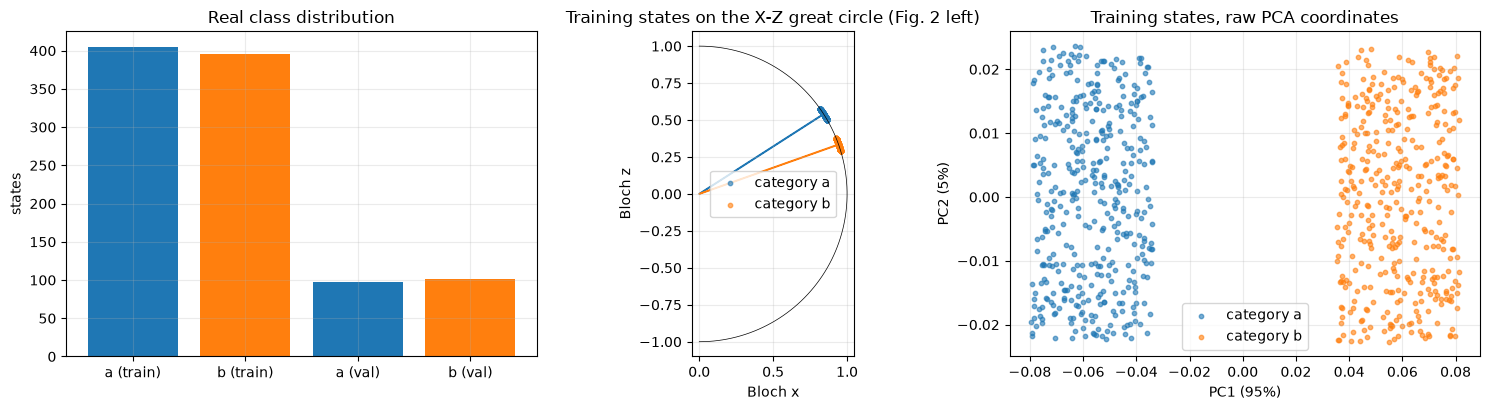

The circuit takes the quantum state itself as input (no angle encoding), so no [0, pi] rescaling of the PCA coordinates is needed.


In [8]:
# ---------------- 7.1 quantum bits classification ----------------
psi_tr, y_tr, ex_tr = D["qubit"][0]; psi_va, y_va, _ = D["qubit"][1]
feat_names = ["Re<0|psi>", "Im<0|psi>", "Re<1|psi>", "Im<1|psi>"]
F_tr = np.column_stack([psi_tr.real[:, 0], psi_tr.imag[:, 0], psi_tr.real[:, 1], psi_tr.imag[:, 1]])
print("qubit data: train state matrix", psi_tr.shape, "| validation", psi_va.shape, "| real feature matrix", F_tr.shape)
print("features:", feat_names, "| Bloch coordinates: [x, y, z]")
print("original labels: 0 = category a (centre at polar angle 1.00 rad), 1 = category b (1.23 rad)")
print("class counts train:", {int(k): int(n) for k, n in zip(*np.unique(y_tr, return_counts=True))}, "| validation:", {int(k): int(n) for k, n in zip(*np.unique(y_va, return_counts=True))})
bl_tr = bloch(psi_tr)
pca_q = PCA(n_components=2, random_state=SEED).fit(F_tr)                 # fitted on the training split only
Z_tr = pca_q.transform(F_tr)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].bar(["a (train)", "b (train)", "a (val)", "b (val)"], [np.sum(y_tr == 0), np.sum(y_tr == 1), np.sum(y_va == 0), np.sum(y_va == 1)], color=["tab:blue", "tab:orange"] * 2)
ax[0].set_title("Real class distribution"); ax[0].set_ylabel("states")
for c, col, nm in ((0, "tab:blue", "category a"), (1, "tab:orange", "category b")):
    ax[1].scatter(bl_tr[y_tr == c, 0], bl_tr[y_tr == c, 2], s=10, c=col, alpha=0.6, label=nm)
for th_, col in ((1.0, "tab:blue"), (1.23, "tab:orange")):
    ax[1].arrow(0, 0, math.sin(th_), math.cos(th_), color=col, width=0.004, length_includes_head=True)
tt = np.linspace(0, PI, 100); ax[1].plot(np.sin(tt), np.cos(tt), "k-", lw=0.5)
ax[1].set_xlabel("Bloch x"); ax[1].set_ylabel("Bloch z"); ax[1].set_title("Training states on the X-Z great circle (Fig. 2 left)"); ax[1].legend(); ax[1].set_aspect("equal")
for c, col, nm in ((0, "tab:blue", "category a"), (1, "tab:orange", "category b")):
    ax[2].scatter(Z_tr[y_tr == c, 0], Z_tr[y_tr == c, 1], s=10, c=col, alpha=0.6, label=nm)
ax[2].set_xlabel(f"PC1 ({pca_q.explained_variance_ratio_[0]:.0%})"); ax[2].set_ylabel(f"PC2 ({pca_q.explained_variance_ratio_[1]:.0%})")
ax[2].set_title("Training states, raw PCA coordinates"); ax[2].legend()
plt.tight_layout(); plt.show()
print("The circuit takes the quantum state itself as input (no angle encoding), so no [0, pi] rescaling of the PCA coordinates is needed.")

### 7.2 Quantum phase recognition

Left: class counts. Middle: the Hamiltonian plane, with the region where the string order parameter exceeds its critical value shaded green (SPT phase `P`) and the rest red; squares are the training line `h2 = 0`, crosses/dots the two validation rectangles, all coloured by their ground-truth label. Right: the ground-state vectors in PCA coordinates.

QPR data: train state matrix (1000, 64) | validation (400, 64) | features = 64 real amplitudes <b|psi> (the ground states are real), b = 000000 ... 111111
original labels: 0 = inside the Z2xZ2 SPT phase P, 1 = outside P
class counts train: {0: 833, 1: 167} | validation: {0: 237, 1: 163}
train: h2/J = 0, h1/J from 0.0012 to 1.2 | validation rectangles (h1, h2): [((0.5, 1.2), (0.0, 0.6)), ((0.0, 0.8), (-1.0, -0.5))]


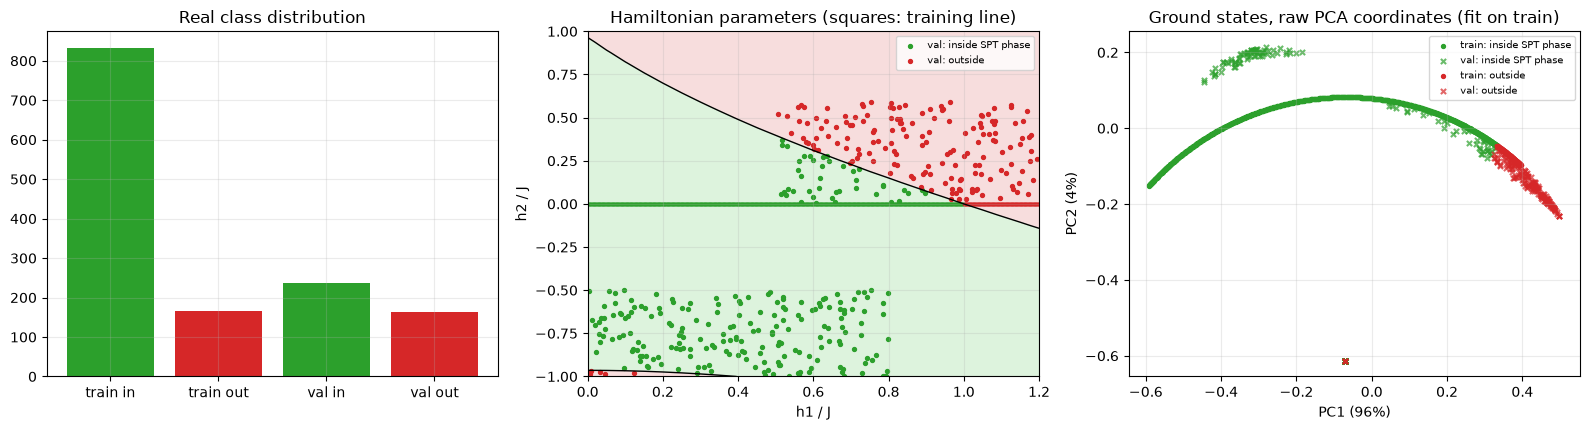

Amplitudes of states enter the circuit directly (no angle encoding), so no [0, pi] rescaling is applicable.


In [9]:
# ---------------- 7.2 quantum phase recognition ----------------
(psi_tr, y_tr, h_tr), (psi_va, y_va, h_va) = D["qpr"]
print("QPR data: train state matrix", psi_tr.shape, "| validation", psi_va.shape, "| features = 64 real amplitudes <b|psi> (the ground states are real), b = 000000 ... 111111")
print("original labels: 0 = inside the Z2xZ2 SPT phase P, 1 = outside P")
print("class counts train:", {int(k): int(n) for k, n in zip(*np.unique(y_tr, return_counts=True))}, "| validation:", {int(k): int(n) for k, n in zip(*np.unique(y_va, return_counts=True))})
print("train: h2/J = 0, h1/J from", h_tr[0, 0].round(4), "to", h_tr[-1, 0].round(4), "| validation rectangles (h1, h2):", QPR_RECT)
G1, G2 = np.meshgrid(np.linspace(0, 1.2, 25), np.linspace(-1, 1, 33))
SO = np.array([[string_order(ground_state(a, b)) for a in G1[0]] for b in G2[:, 0]])
pca_p = PCA(n_components=2, random_state=SEED).fit(psi_tr.real)
Z_tr, Z_va = pca_p.transform(psi_tr.real), pca_p.transform(psi_va.real)
names = {0: "inside SPT phase", 1: "outside"}; cols = {0: "tab:green", 1: "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].bar(["train in", "train out", "val in", "val out"], [np.sum(y_tr == 0), np.sum(y_tr == 1), np.sum(y_va == 0), np.sum(y_va == 1)], color=["tab:green", "tab:red"] * 2)
ax[0].set_title("Real class distribution")
cs = ax[1].contourf(G1, G2, SO, levels=[0, S_CRIT, 1.01], colors=["#f6d5d5", "#d5f0d5"], alpha=0.8)
ax[1].contour(G1, G2, SO, levels=[S_CRIT], colors="k", linewidths=1)
for c in (0, 1):
    ax[1].scatter(h_va[y_va == c, 0], h_va[y_va == c, 1], s=8, c=cols[c], label=f"val: {names[c]}")
    ax[1].scatter(h_tr[y_tr == c, 0], h_tr[y_tr == c, 1], s=4, c=cols[c], marker="s")
ax[1].set_xlabel("h1 / J"); ax[1].set_ylabel("h2 / J"); ax[1].set_title("Hamiltonian parameters (squares: training line)"); ax[1].legend(fontsize=7)
for c in (0, 1):
    ax[2].scatter(Z_tr[y_tr == c, 0], Z_tr[y_tr == c, 1], s=8, c=cols[c], label=f"train: {names[c]}")
    ax[2].scatter(Z_va[y_va == c, 0], Z_va[y_va == c, 1], s=14, c=cols[c], marker="x", label=f"val: {names[c]}", alpha=0.7)
ax[2].set_xlabel(f"PC1 ({pca_p.explained_variance_ratio_[0]:.0%})"); ax[2].set_ylabel(f"PC2 ({pca_p.explained_variance_ratio_[1]:.0%})")
ax[2].set_title("Ground states, raw PCA coordinates (fit on train)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Amplitudes of states enter the circuit directly (no angle encoding), so no [0, pi] rescaling is applicable.")

### 7.3 Cluster excitation detection

cluster data: train state matrix (840, 64) | validation (360, 64) | features: Re and Im of the 64 amplitudes (128 real features)
original labels: 1 = not excited (-pi/2 <= theta <= pi/2), 0 = excited (|theta| > pi/2); rotation Rx(theta) on qubit 2
class counts train: {0: 431, 1: 409} | validation: {0: 191, 1: 169}


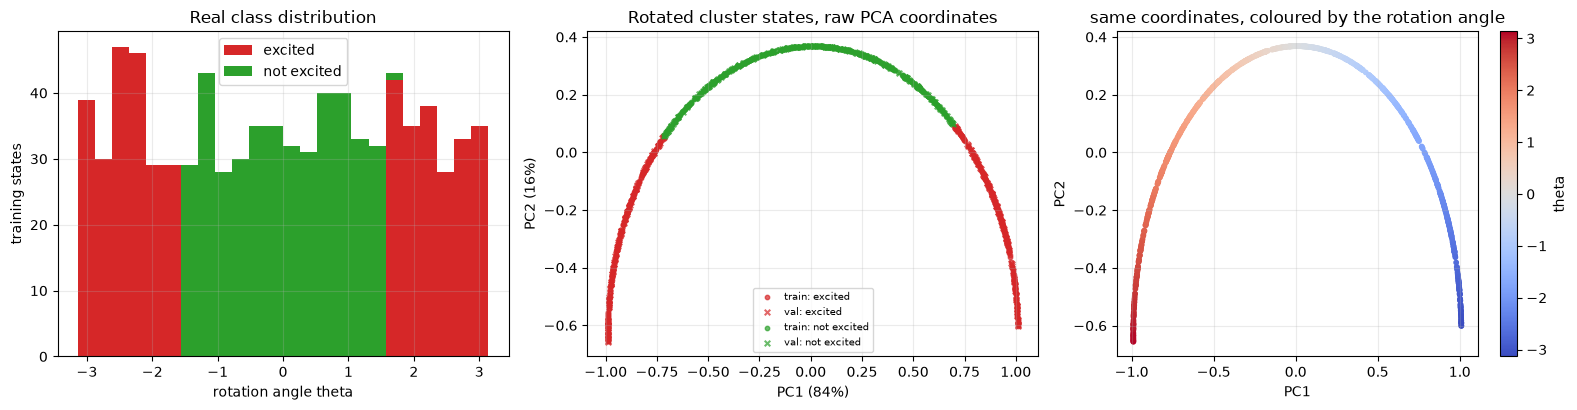

Amplitudes of states enter the circuit directly (no angle encoding), so no [0, pi] rescaling is applicable.


In [10]:
# ---------------- 7.3 cluster excitation detection ----------------
(psi_tr, y_tr, th_tr), (psi_va, y_va, th_va) = D["cluster"]
F_tr = np.hstack([psi_tr.real, psi_tr.imag])
print("cluster data: train state matrix", psi_tr.shape, "| validation", psi_va.shape, "| features: Re and Im of the 64 amplitudes (128 real features)")
print("original labels: 1 = not excited (-pi/2 <= theta <= pi/2), 0 = excited (|theta| > pi/2); rotation Rx(theta) on qubit", EXC_QUBIT)
print("class counts train:", {int(k): int(n) for k, n in zip(*np.unique(y_tr, return_counts=True))}, "| validation:", {int(k): int(n) for k, n in zip(*np.unique(y_va, return_counts=True))})
pca_c = PCA(n_components=2, random_state=SEED).fit(F_tr)
Z_tr = pca_c.transform(F_tr); Z_va = pca_c.transform(np.hstack([psi_va.real, psi_va.imag]))
nm = {0: "excited", 1: "not excited"}; cc = {0: "tab:red", 1: "tab:green"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist([th_tr[y_tr == 0], th_tr[y_tr == 1]], bins=24, color=[cc[0], cc[1]], label=[nm[0], nm[1]], stacked=True)
ax[0].set_xlabel("rotation angle theta"); ax[0].set_ylabel("training states"); ax[0].set_title("Real class distribution"); ax[0].legend()
for c in (0, 1):
    ax[1].scatter(Z_tr[y_tr == c, 0], Z_tr[y_tr == c, 1], s=10, c=cc[c], alpha=0.7, label=f"train: {nm[c]}")
    ax[1].scatter(Z_va[y_va == c, 0], Z_va[y_va == c, 1], s=16, c=cc[c], marker="x", alpha=0.7, label=f"val: {nm[c]}")
ax[1].set_xlabel(f"PC1 ({pca_c.explained_variance_ratio_[0]:.0%})"); ax[1].set_ylabel(f"PC2 ({pca_c.explained_variance_ratio_[1]:.0%})")
ax[1].set_title("Rotated cluster states, raw PCA coordinates"); ax[1].legend(fontsize=7)
sc = ax[2].scatter(Z_tr[:, 0], Z_tr[:, 1], c=th_tr, cmap="coolwarm", s=10)
plt.colorbar(sc, ax=ax[2], label="theta"); ax[2].set_title("same coordinates, coloured by the rotation angle"); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); plt.show()
print("Amplitudes of states enter the circuit directly (no angle encoding), so no [0, pi] rescaling is applicable.")

### 7.4 MNIST digits 3 and 6

MNIST data: train (1000, 256) | validation (400, 256) | features: 256 pixel intensities pix_r_c (16 x 16), amplitude-encoded and l2-normalised
raw images: (1000, 28, 28) uint8 0..255 -> resized to (16, 16) | original MNIST digits kept: [3, 6]
original labels: digit 3 -> output 1, digit 6 -> output 0
class counts train: {3: 500, 6: 500} | validation: {3: 200, 6: 200}


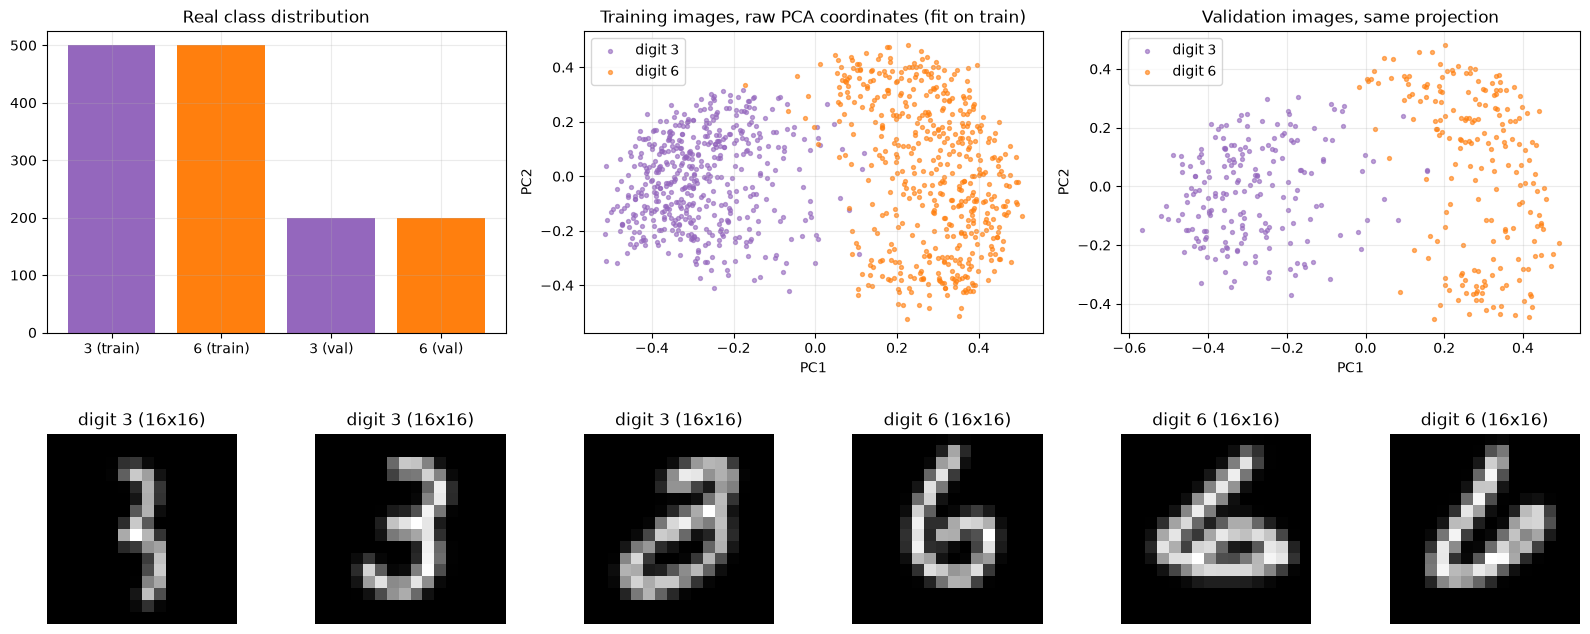

Amplitude encoding feeds the normalised pixel vector to the circuit as a state; no angle encoding, so no [0, pi] rescaling is applicable.


In [11]:
# ---------------- 7.4 MNIST 3 versus 6 ----------------
(psi_tr, y_tr, ex_tr), (psi_va, y_va, ex_va) = D["mnist"]
print("MNIST data: train", psi_tr.shape, "| validation", psi_va.shape, "| features: 256 pixel intensities pix_r_c (16 x 16), amplitude-encoded and l2-normalised")
print("raw images:", ex_tr["img28"].shape, "uint8 0..255 -> resized to", ex_tr["img16"].shape[1:], "| original MNIST digits kept:", sorted(set(ex_tr["digit"].tolist())))
print("original labels: digit 3 -> output 1, digit 6 -> output 0")
print("class counts train:", {int(d): int((ex_tr['digit'] == d).sum()) for d in (3, 6)}, "| validation:", {int(d): int((ex_va['digit'] == d).sum()) for d in (3, 6)})
pca_m = PCA(n_components=2, random_state=SEED).fit(psi_tr.real)
Z_tr, Z_va = pca_m.transform(psi_tr.real), pca_m.transform(psi_va.real)
fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(2, 6)
ax0 = fig.add_subplot(gs[0, 0:2]); ax0.bar(["3 (train)", "6 (train)", "3 (val)", "6 (val)"], [int((ex_tr['digit'] == 3).sum()), int((ex_tr['digit'] == 6).sum()), int((ex_va['digit'] == 3).sum()), int((ex_va['digit'] == 6).sum())], color=["tab:purple", "tab:orange"] * 2)
ax0.set_title("Real class distribution")
ax1 = fig.add_subplot(gs[0, 2:4]); ax2 = fig.add_subplot(gs[0, 4:6])
for d, col in ((3, "tab:purple"), (6, "tab:orange")):
    m = ex_tr["digit"] == d
    ax1.scatter(Z_tr[m, 0], Z_tr[m, 1], s=8, c=col, alpha=0.6, label=f"digit {d}")
ax1.set_title("Training images, raw PCA coordinates (fit on train)"); ax1.legend(); ax1.set_xlabel("PC1"); ax1.set_ylabel("PC2")
for d, col in ((3, "tab:purple"), (6, "tab:orange")):
    m = ex_va["digit"] == d
    ax2.scatter(Z_va[m, 0], Z_va[m, 1], s=8, c=col, alpha=0.6, label=f"digit {d}")
ax2.set_title("Validation images, same projection"); ax2.legend(); ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2")
for j in range(6):                                      # sample images: raw 28 x 28 and the 16 x 16 version that is amplitude-encoded
    for r, d in enumerate((3, 6)):
        pass
sel = [np.where(ex_tr["digit"] == d)[0][:3] for d in (3, 6)]
for j, i in enumerate(np.concatenate(sel)):
    a = fig.add_subplot(gs[1, j]); a.imshow(ex_tr["img16"][i], cmap="gray"); a.set_title(f"digit {ex_tr['digit'][i]} (16x16)"); a.axis("off")
plt.tight_layout(); plt.show()
print("Amplitude encoding feeds the normalised pixel vector to the circuit as a state; no angle encoding, so no [0, pi] rescaling is applicable.")

## Part 3. The four classifiers as circuits (exact simulator + Qiskit)

The paper trains with TensorFlow Quantum. Here every circuit is a short list of gates; a small exact **state-vector simulator in PyTorch** applies them (fused two-qubit blocks) so that Adam gets exact gradients. The very same circuits are built in **Qiskit** further below, and the notebook *asserts* that the two have the same unitary, so what is drawn and executed is what was trained.

* **Single qubit:** `Ry(theta)`, then a Z measurement (outcome 0 = category a, outcome 1 = category b).
* **QPR QCNN (6 qubits):** `U1` on bonds (0,1),(2,3),(4,5); `U2` on (1,2),(3,4); measurement-controlled pooling `V1` (qubits 0, 2, 4 control qubits 1, 3, 5); `U3` on (1,3),(3,5); pooling `V2` (qubit 1 controls 3); fully connected `F` on (3,5); a Hadamard on qubit 5 and a Z measurement, i.e. a measurement in the `{|+>, |->}` basis. `U` and `F` are `exp(-i sum_j theta_j Lambda_j)` over the 15 two-qubit Pauli strings, `V` is `exp(-i sum_j theta_j sigma_j)` (3 parameters). Pooling in the paper is a mid-circuit measurement that controls a unitary; by the deferred-measurement principle it is the controlled unitary used here, and the control qubit is never read again.
* **Cluster and MNIST QCNNs (6 and 8 qubits):** the TensorFlow Quantum building blocks. `two_qubit_unitary`: one-qubit `X^a Y^b Z^c` unitaries, `ZZ^t YY^t XX^t`, one-qubit unitaries (15 parameters); `two_qubit_pool`: basis changes, `CNOT(source -> sink)`, inverse basis change (6 parameters). Three convolution layers (all neighbouring pairs, weights shared) alternate with three pooling layers that halve the register; the last remaining qubit is read out (Z basis for the cluster task, `{|+>, |->}` basis for MNIST).

**Training.** Full-batch Adam on the MSE of Eq. (8), `L = (1/C) ||f - c||^2` with `f_k = tr(M_k E(rho))`; for two classes this is `(1 - p_true)^2`. Class-balanced weights are used (see the table at the top), a cosine learning-rate schedule and a few random restarts.

In [12]:
# ---------------------------------------------------------------------------------------------
# Part 3: the four trained circuits.  One small exact state-vector simulator in PyTorch (so that Adam gets exact gradients),
# and for each model the equivalent Qiskit circuit; Part 4 asserts that the two are the same unitary.
# ---------------------------------------------------------------------------------------------
CDT = torch.complex128
_I2 = torch.eye(2, dtype=CDT); _I4 = torch.eye(4, dtype=CDT)
_X = torch.tensor([[0, 1], [1, 0]], dtype=CDT); _Y = torch.tensor([[0, -1j], [1j, 0]], dtype=CDT); _Z = torch.tensor([[1, 0], [0, -1]], dtype=CDT)
_H = torch.tensor([[1, 1], [1, -1]], dtype=CDT) / math.sqrt(2)
_CNOT = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=CDT)   # control = first qubit of the pair
_XX, _YY, _ZZ = torch.kron(_X, _X), torch.kron(_Y, _Y), torch.kron(_Z, _Z)
PAULI2 = [torch.kron(a, b) for a in (_I2, _X, _Y, _Z) for b in (_I2, _X, _Y, _Z)][1:]      # 15 two-qubit Pauli strings = a basis of su(4)
PAULI1 = [_X, _Y, _Z]

def rot1(P, a):  return torch.cos(a / 2) * _I2 - 1j * torch.sin(a / 2) * P          # exp(-i a P / 2)
def rot2(P, a):  return torch.cos(a / 2) * _I4 - 1j * torch.sin(a / 2) * P

def u1q(p):
    """TFQ one_qubit_unitary: X**p0, then Y**p1, then Z**p2 (= Rx(pi p0), Ry(pi p1), Rz(pi p2) up to a global phase)."""
    return rot1(_Z, PI * p[2]) @ rot1(_Y, PI * p[1]) @ rot1(_X, PI * p[0])

def u2q(p):
    """TFQ two_qubit_unitary (15 parameters): 1q unitaries, ZZ**p6, YY**p7, XX**p8, 1q unitaries."""
    A = torch.kron(u1q(p[0:3]), u1q(p[3:6]))
    M = rot2(_XX, PI * p[8]) @ rot2(_YY, PI * p[7]) @ rot2(_ZZ, PI * p[6])
    B = torch.kron(u1q(p[9:12]), u1q(p[12:15]))
    return B @ M @ A

def pool2(p):
    """TFQ two_qubit_pool on (source, sink): basis changes, CNOT(source -> sink), inverse of the sink basis change (6 parameters)."""
    sink = u1q(p[0:3]); src = u1q(p[3:6])
    return torch.kron(_I2, sink.conj().T.contiguous()) @ _CNOT @ torch.kron(src, sink)

def gm_u(p):
    """exp(-i sum_j theta_j Lambda_j) on two qubits, Lambda_j the 15 Pauli strings (a generalised Gell-Mann basis of su(4)): 15 parameters."""
    G = sum(p[j] * PAULI2[j] for j in range(15))
    return torch.linalg.matrix_exp(-1j * G)

def gm_cv(p):
    """Measurement-controlled unitary V = exp(-i sum_j theta_j sigma_j) (3 parameters): applied on the target iff the control qubit is |1>
    (deferred-measurement form of the pooling layer of Cong et al.)."""
    V = torch.linalg.matrix_exp(-1j * sum(p[j] * PAULI1[j] for j in range(3)))
    out = torch.zeros(4, 4, dtype=CDT); out[:2, :2] = _I2; out[2:, 2:] = V
    return out

def ry1(p):  return rot1(_Y, p[0])

BLOCKS = {"u2q": (u2q, 15), "pool2": (pool2, 6), "gm_u": (gm_u, 15), "gm_cv": (gm_cv, 3), "ry1": (ry1, 1)}

def apply_gate(states, M, wires, n):
    """states (B, 2^n) complex; M is 2x2 (1 wire) or 4x4 (2 wires, first wire = most significant bit of the pair index). Qubit q sits on tensor axis n - q."""
    B = states.shape[0]
    t = states.reshape((B,) + (2,) * n)
    k = len(wires)
    src = [n - w for w in wires]; dst = list(range(1, k + 1))
    t = torch.movedim(t, src, dst)
    sh = t.shape
    t = torch.einsum("ij,bjr->bir", M, t.reshape(B, 2 ** k, -1)).reshape(sh)
    return torch.movedim(t, dst, src).reshape(B, -1)

class QModel:
    """A circuit = list of ops (kind, block_id, wires); block_id selects a parameter slice that is SHARED by every op using it (weight sharing)."""
    def __init__(self, name, n, ops, blocks, readout, readout_basis, outcome_of_class=None):
        self.name, self.n, self.ops, self.readout, self.readout_basis = name, n, ops, readout, readout_basis
        self.blocks = blocks                         # block_id -> (kind, offset)
        self.n_params = sum(BLOCKS[k][1] for k, _ in blocks.values())

    def _mats(self, theta):
        return {b: BLOCKS[k][0](theta[off: off + BLOCKS[k][1]]) for b, (k, off) in self.blocks.items()}

    def run(self, psi, theta):
        mats = self._mats(theta)
        s = psi
        for kind, b, wires in self.ops:
            s = apply_gate(s, _H if kind == "h" else mats[b], wires, self.n)
        return s

    def prob1(self, psi, theta):
        """Probability of outcome 1 on the readout qubit (after a Hadamard when the paper measures in the {|+>, |->} basis)."""
        d = 2 ** self.n
        WT = self.run(torch.eye(d, dtype=CDT), theta)          # row j = W|j>, i.e. WT = W^T: cheaper than pushing every sample through the gates
        mask = torch.as_tensor(((np.arange(d) >> self.readout) & 1) == 1)
        amp = psi @ WT[:, mask]                                 # amplitudes of the basis states whose readout bit is 1
        return (amp.conj() * amp).real.sum(1)

    def unitary(self, theta):
        """The full 2^n x 2^n unitary W of the circuit (columns = images of the basis states) as a NumPy array."""
        with torch.no_grad():
            d = 2 ** self.n
            out = self.run(torch.eye(d, dtype=CDT), torch.as_tensor(theta))
        return out.T.numpy().copy()

    def effects(self, theta):
        """Heisenberg-picture effects A_k = W^dagger (|k><k|_readout x I) W for outcomes k = 0, 1."""
        W = self.unitary(theta)
        idx = np.arange(2 ** self.n)
        bit = (idx >> self.readout) & 1
        return [W[bit == k].conj().T @ W[bit == k] for k in (0, 1)]

def conv_pairs(bits):
    return list(zip(bits[0::2], bits[1::2])) + list(zip(bits[1::2], bits[2::2] + [bits[0]]))

def tfq_qcnn(name, n, plan, readout, readout_basis="Z"):
    """TensorFlow-Quantum QCNN: conv layers (two_qubit_unitary on every neighbouring pair, 15 shared parameters) and pooling layers
    (two_qubit_pool, 6 shared parameters). plan = [('conv', bits), ('pool', sources, sinks), ...]."""
    ops, blocks, off = [], {}, 0
    for li, step in enumerate(plan):
        if step[0] == "conv":
            blocks[li] = ("u2q", off); off += 15
            ops += [("u2q", li, pr) for pr in conv_pairs(list(step[1]))]
        else:
            blocks[li] = ("pool2", off); off += 6
            ops += [("pool2", li, (s, t)) for s, t in zip(step[1], step[2])]
    if readout_basis == "X":
        ops.append(("h", None, (readout,)))
    return QModel(name, n, ops, blocks, readout, readout_basis)

def model_qubit():
    return QModel("qubit classifier", 1, [("ry1", 0, (0,))], {0: ("ry1", 0)}, 0, "Z")

def model_qpr():
    """6-qubit QCNN in the style of Cong et al. / Fig. 4b: conv U1 (even bonds), U2 (odd bonds), measurement-controlled pooling V1, conv U3,
    pooling V2, fully connected F on the last two qubits, readout in the {|+>,|->} basis. CHOICE: gate sharing per layer (66 parameters; the paper
    reports 114, its Fig. 4b cannot be recovered from the text)."""
    ops = [("gm_u", 0, (0, 1)), ("gm_u", 0, (2, 3)), ("gm_u", 0, (4, 5)),
           ("gm_u", 1, (1, 2)), ("gm_u", 1, (3, 4)),
           ("gm_cv", 2, (0, 1)), ("gm_cv", 2, (2, 3)), ("gm_cv", 2, (4, 5)),
           ("gm_u", 3, (1, 3)), ("gm_u", 3, (3, 5)),
           ("gm_cv", 4, (1, 3)),
           ("gm_u", 5, (3, 5)), ("h", None, (5,))]
    blocks = {0: ("gm_u", 0), 1: ("gm_u", 15), 2: ("gm_cv", 30), 3: ("gm_u", 33), 4: ("gm_cv", 48), 5: ("gm_u", 51)}
    return QModel("QPR QCNN", 6, ops, blocks, 5, "X")

def model_cluster():
    plan = [("conv", range(0, 6)), ("pool", [0, 1, 2], [3, 4, 5]), ("conv", [3, 4, 5]), ("pool", [3], [4]), ("conv", [4, 5]), ("pool", [4], [5])]
    return tfq_qcnn("cluster QCNN", 6, plan, 5, "Z")

def model_mnist():
    plan = [("conv", range(0, 8)), ("pool", [0, 1, 2, 3], [4, 5, 6, 7]), ("conv", [4, 5, 6, 7]), ("pool", [4, 5], [6, 7]),
            ("conv", [6, 7]), ("pool", [6], [7])]
    return tfq_qcnn("MNIST QCNN", 8, plan, 7, "X")

MODEL_BUILDERS = {"qubit": model_qubit, "qpr": model_qpr, "cluster": model_cluster, "mnist": model_mnist}
for k_, f_ in MODEL_BUILDERS.items():
    m_ = f_(); print(f"{k_:8s}: {m_.n} qubits, {len(m_.ops)} gate blocks, {m_.n_params} trainable parameters, readout qubit {m_.readout} ({m_.readout_basis} basis)")

# ---------------------------------------------------------------------------------------------
# Training: Adam on the MSE of Eq. (8),  L = (1/C) || f(theta, rho) - c ||^2  with f_k = tr(M_k E(rho)).
# ---------------------------------------------------------------------------------------------
def outcome_probs_np(model, theta, psi):
    with torch.no_grad():
        p1 = model.prob1(torch.as_tensor(psi, dtype=CDT), torch.as_tensor(theta)).numpy()
    return np.stack([1 - p1, p1], 1)

def train_model(model, psi, y, epochs, lr, init_scale, seed, restarts, balanced=True):
    """Full-batch Adam, cosine learning-rate decay. The restart with the lowest final training loss is kept (CHOICE: the paper reports one run)."""
    psi_t = torch.as_tensor(psi, dtype=CDT); y_t = torch.as_tensor(y)
    # CHOICE: class-balanced weights (each class contributes half of the loss). The QPR training line is 83% / 17% (h1 < 1 versus h1 > 1); with the plain
    # mean the optimiser settles in the trivial "everything is phase P" minimum. For balanced data (the other three tasks) the weights are all equal to 1/N.
    n1 = int((y == 1).sum()); n0 = len(y) - n1
    wt = (torch.where(y_t == 1, 0.5 / n1, 0.5 / n0) if balanced else torch.full((len(y),), 1.0 / len(y))).to(torch.float64)
    best = None
    for r in range(restarts):
        g = torch.Generator().manual_seed(seed * 100 + r)
        theta = (init_scale * torch.randn(model.n_params, generator=g, dtype=torch.float64)).requires_grad_()
        opt = torch.optim.Adam([theta], lr=lr)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.02)
        hist = []
        for ep in range(epochs):
            opt.zero_grad()
            p1 = model.prob1(psi_t, theta)
            pc = torch.where(y_t == 1, p1, 1 - p1)
            loss = (wt * (1 - pc) ** 2).sum()                 # (1/2)[(1-p_c)^2 + p_other^2] = (1-p_c)^2 for two classes
            loss.backward(); opt.step(); sched.step()
            hist.append(float(loss))
        if best is None or hist[-1] < best[1][-1]:
            best = (theta.detach().numpy().copy(), hist)
    return best

def accuracy(model, theta, psi, y):
    P = outcome_probs_np(model, theta, psi)
    return float((P.argmax(1) == y).mean())

qubit   : 1 qubits, 1 gate blocks, 1 trainable parameters, readout qubit 0 (Z basis)
qpr     : 6 qubits, 13 gate blocks, 66 trainable parameters, readout qubit 5 (X basis)
cluster : 6 qubits, 15 gate blocks, 63 trainable parameters, readout qubit 5 (Z basis)
mnist   : 8 qubits, 22 gate blocks, 63 trainable parameters, readout qubit 7 (X basis)


## Part 4. Training the classifiers

Each model is trained on the training split and scored on both splits. A classifier is "well trained" in the paper if both accuracies are at least 95% (Section 3.1); the learned angle of the single-qubit classifier is compared with the paper's `0.4835`.

seed 42 | qubit    |   1 params | 300 epochs x 3 restarts | final loss 0.1962 | train acc 100.00% | val acc 100.00% | 13s


seed 42 | qpr      |  66 params | 600 epochs x 3 restarts | final loss 0.1182 | train acc 77.80% | val acc 61.00% | 96s


seed 42 | cluster  |  63 params | 500 epochs x 2 restarts | final loss 0.0553 | train acc 99.76% | val acc 99.72% | 88s


seed 42 | mnist    |  63 params | 250 epochs x 2 restarts | final loss 0.1160 | train acc 97.40% | val acc 96.50% | 179s


seed 43 | qubit    |   1 params | 300 epochs x 3 restarts | final loss 0.1958 | train acc 100.00% | val acc 100.00% | 4s


...

seed 43 | mnist    |  63 params | 250 epochs x 2 restarts | final loss 0.1088 | train acc 97.90% | val acc 98.75% | 166s


seed 44 | qubit    |   1 params | 300 epochs x 3 restarts | final loss 0.1964 | train acc 100.00% | val acc 100.00% | 4s


seed 44 | qpr      |  66 params | 600 epochs x 3 restarts | final loss 0.1224 | train acc 77.10% | val acc 85.75% | 111s


seed 44 | cluster  |  63 params | 500 epochs x 2 restarts | final loss 0.0601 | train acc 99.88% | val acc 100.00% | 98s


seed 44 | mnist    |  63 params | 250 epochs x 2 restarts | final loss 0.1199 | train acc 96.60% | val acc 94.50% | 176s


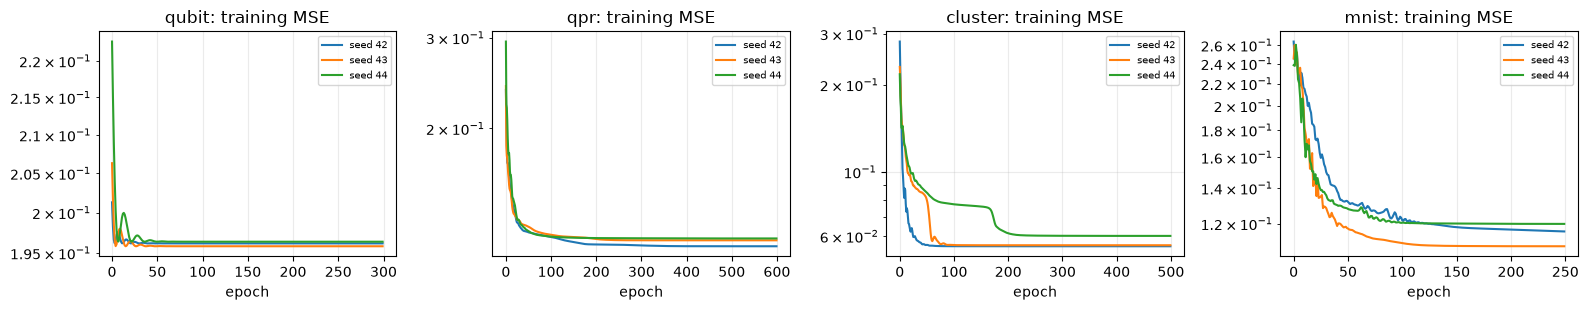

learned angle of the single-qubit classifier Ry(theta): theta = [0.4558 0.4573 0.4561] (paper: 0.4835)


In [13]:
# ---------------------------------------------------------------------------------------------
# Part 4: train the four classifiers (full batch Adam on the MSE), report training / validation accuracy.
# ---------------------------------------------------------------------------------------------
RUN = {}
def fit_all(seed):
    Dd = get_datasets(seed)
    for task in MODEL_BUILDERS:
        tr, va = Dd[task]
        m = MODEL_BUILDERS[task]()
        t0 = time.time()
        th, hist = train_model(m, tr[0], tr[1], EPOCHS[task], LR[task], INIT_SCALE[task], seed, RESTARTS[task])
        RUN[(task, seed)] = dict(model=m, theta=th, hist=hist, acc_tr=accuracy(m, th, tr[0], tr[1]), acc_va=accuracy(m, th, va[0], va[1]), secs=time.time() - t0)
        r = RUN[(task, seed)]
        print(f"seed {seed} | {task:8s} | {m.n_params:3d} params | {EPOCHS[task]} epochs x {RESTARTS[task]} restarts | final loss {hist[-1]:.4f} | "
              f"train acc {100 * r['acc_tr']:.2f}% | val acc {100 * r['acc_va']:.2f}% | {r['secs']:.0f}s")

for sd in SEEDS:
    fit_all(sd)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, task in zip(ax, MODEL_BUILDERS):
    for sd in SEEDS:
        a.plot(RUN[(task, sd)]["hist"], label=f"seed {sd}")
    a.set_title(f"{task}: training MSE"); a.set_xlabel("epoch"); a.set_yscale("log"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("learned angle of the single-qubit classifier Ry(theta): theta =", np.round([RUN[("qubit", sd)]["theta"][0] for sd in SEEDS], 4), "(paper: 0.4835)")

plain MSE : final loss 0.0869 | train acc 83.30% | val acc 78.75% | smallest P(phase P) on the training line = 0.544 (above 0.5 means that every state is called 'inside P')
balanced  : final loss 0.1182 | train acc 77.80% | val acc 61.00% | smallest P(phase P) = 0.274


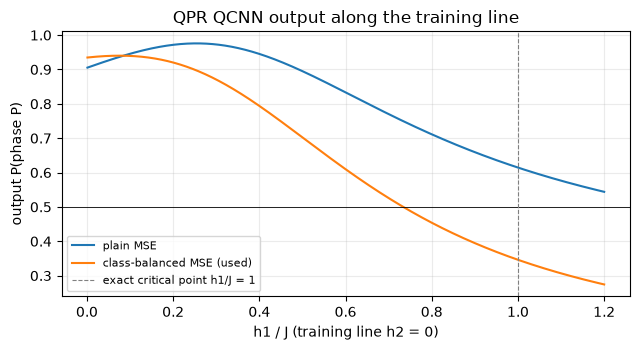

fidelity of the ground states at h1/J = 0.9 and 1.1: 0.9906  ->  any outcome probability can differ between them by at most the trace distance sqrt(1 - F) = 0.097


In [14]:
# Ablation for the class-balanced weights: the same QPR QCNN trained with the plain (unweighted) MSE of Eq. (8).
tr_q, va_q = get_datasets(SEED)["qpr"]
m_plain = MODEL_BUILDERS["qpr"]()
th_plain, h_plain = train_model(m_plain, tr_q[0], tr_q[1], max(200, EPOCHS["qpr"] // 2), LR["qpr"], INIT_SCALE["qpr"], SEED, 1, balanced=False)
P_plain = outcome_probs_np(m_plain, th_plain, tr_q[0])
print(f"plain MSE : final loss {h_plain[-1]:.4f} | train acc {100 * accuracy(m_plain, th_plain, tr_q[0], tr_q[1]):.2f}% | val acc {100 * accuracy(m_plain, th_plain, va_q[0], va_q[1]):.2f}% "
      f"| smallest P(phase P) on the training line = {P_plain[:, 0].min():.3f} (above 0.5 means that every state is called 'inside P')")
r_ = RUN[("qpr", SEED)]
P_bal = outcome_probs_np(r_["model"], r_["theta"], tr_q[0])
print(f"balanced  : final loss {r_['hist'][-1]:.4f} | train acc {100 * r_['acc_tr']:.2f}% | val acc {100 * r_['acc_va']:.2f}% | smallest P(phase P) = {P_bal[:, 0].min():.3f}")
h1_line = tr_q[2][:, 0]
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.6))
ax.plot(h1_line, P_plain[:, 0], label="plain MSE"); ax.plot(h1_line, P_bal[:, 0], label="class-balanced MSE (used)")
ax.axhline(0.5, color="k", lw=0.6); ax.axvline(1.0, color="gray", ls="--", lw=0.8, label="exact critical point h1/J = 1")
ax.set_xlabel("h1 / J (training line h2 = 0)"); ax.set_ylabel("output P(phase P)"); ax.set_title("QPR QCNN output along the training line"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Why a sharp phase boundary cannot be learned from these states: the ground states change very slowly with h1/J.
i9, i11 = int(np.argmin(np.abs(h1_line - 0.9))), int(np.argmin(np.abs(h1_line - 1.1)))
F911 = abs(np.vdot(tr_q[0][i9], tr_q[0][i11])) ** 2
print(f"fidelity of the ground states at h1/J = 0.9 and 1.1: {F911:.4f}  ->  any outcome probability can differ between them by at most the trace distance sqrt(1 - F) = {math.sqrt(1 - F911):.3f}")

## Quantum Circuit Architecture

The circuits below are the Qiskit circuits that are **executed** in this notebook (an assertion compares each one with the simulator that trained it: same unitary up to a global phase, same outcome probabilities on validation states, and the data-preparation circuits reproduce the data sets' states). Each drawing shows the encoding / state preparation, the parametrised layers (one labelled box per layer; the last figures expand one convolution block and one pooling block into their gates), the entanglement and the final measurement of the readout qubit. For every model the cell prints the number of qubits, the circuit depth (as built, and after transpiling to `{rz, sx, x, cx}`), the number of rotation angles in the circuit and the number of **independent trainable parameters** (smaller because the layers share weights).

**Assumptions where the paper omits circuit details** (also listed in the table at the top): the QPR circuit follows the pooling/convolution pattern of Cong et al. with 66 shared parameters instead of the paper's 114; the cluster and MNIST QCNNs use the TensorFlow Quantum gate set with a halving schedule of three convolution and three pooling layers (63 parameters); the rotated qubit of the cluster task is qubit 2; the QPR and MNIST states are loaded by Qiskit's exact state preparation (the ground state is a classical diagonalisation, the amplitude encoding is a state-preparation block), so their cost is not counted in the depth of the classifier.

In [15]:
# ---------------------------------------------------------------------------------------------
# Qiskit versions of the four circuits (the objects that are drawn and executed), and the equivalence check against the PyTorch simulator.
# ---------------------------------------------------------------------------------------------
from qiskit import ClassicalRegister

def qk_u1q(qc, p, q, inverse=False):
    if not inverse:
        qc.rx(PI * p[0], q); qc.ry(PI * p[1], q); qc.rz(PI * p[2], q)
    else:
        qc.rz(-PI * p[2], q); qc.ry(-PI * p[1], q); qc.rx(-PI * p[0], q)

def qk_op(qc, kind, p, wires, mats):
    if kind == "h":
        qc.h(wires[0])
    elif kind == "ry1":
        qc.ry(float(p[0]), wires[0])
    elif kind == "u2q":
        a, b = wires
        qk_u1q(qc, p[0:3], a); qk_u1q(qc, p[3:6], b)
        qc.rzz(PI * p[6], a, b); qc.ryy(PI * p[7], a, b); qc.rxx(PI * p[8], a, b)
        qk_u1q(qc, p[9:12], a); qk_u1q(qc, p[12:15], b)
    elif kind == "pool2":
        src, sink = wires
        qk_u1q(qc, p[0:3], sink); qk_u1q(qc, p[3:6], src)
        qc.cx(src, sink)
        qk_u1q(qc, p[0:3], sink, inverse=True)
    else:                                            # gm_u / gm_cv: exp(-i sum theta_j Lambda_j) as a 4x4 unitary box
        a, b = wires
        qc.append(UnitaryGate(mats, label="exp(-i sum th.L)" if kind == "gm_u" else "ctrl-V"), [b, a])   # Qiskit lists the least significant qubit first

def clf_circuit(model, theta, hierarchical=False, plan_labels=None):
    """The classifier circuit (no data preparation, no measurement) with the trained parameters bound."""
    n = model.n
    th = torch.as_tensor(theta)
    pnp = {b: theta[off: off + BLOCKS[k][1]] for b, (k, off) in model.blocks.items()}
    mat = {b: BLOCKS[k][0](th[off: off + BLOCKS[k][1]]).detach().numpy() for b, (k, off) in model.blocks.items()}
    qc = QuantumCircuit(n, name=model.name)
    if not hierarchical:
        for kind, b, wires in model.ops:
            qk_op(qc, kind, None if b is None else pnp[b], wires, None if b is None else mat[b])
        return qc
    # hierarchical: consecutive ops that use the same block id form one labelled box on the qubits they touch
    groups, cur = [], None
    for kind, b, wires in model.ops:
        key = (kind if kind == "h" else b)
        if cur is None or cur[0] != key:
            cur = [key, []]; groups.append(cur)
        cur[1].append((kind, b, wires))
    for key, ops in groups:
        touched = sorted({w for _, _, ws in ops for w in ws})
        loc = {w: i for i, w in enumerate(touched)}
        sub = QuantumCircuit(len(touched))
        for kind, b, wires in ops:
            qk_op(sub, kind, None if b is None else pnp[b], tuple(loc[w] for w in wires), None if b is None else mat[b])
        label = "H" if key == "h" else (plan_labels or {}).get(key, f"block {key}")
        qc.append(sub.to_gate(label=label), touched)
    return qc

def equal_up_to_phase(A, B, tol=1e-9):
    ph = np.vdot(B.ravel(), A.ravel()); ph /= abs(ph)
    return float(np.max(np.abs(A - ph * B)))

# ---- data-preparation circuits (the states that enter the classifier) ----
def prep_qubit(ex_angle, ex_tilt):
    qc = QuantumCircuit(1); qc.ry(float(ex_angle), 0); qc.rx(float(ex_tilt), 0); return qc
def prep_cluster(theta):
    qc = QuantumCircuit(NQ_CLU)
    for q in range(NQ_CLU): qc.h(q)
    for q in range(NQ_CLU): qc.cz(q, (q + 1) % NQ_CLU)
    qc.rx(float(theta), EXC_QUBIT); return qc
def prep_state(psi, n, label):
    qc = QuantumCircuit(n); qc.initialize(np.asarray(psi, complex), list(range(n))); return qc      # exact state preparation (Qiskit Initialize)

def full_circuit(prep, clf, readout, measure=True):
    qc = QuantumCircuit(clf.num_qubits, 1 if measure else 0)
    qc.compose(prep, inplace=True)
    qc.barrier()
    qc.compose(clf, inplace=True)
    if measure:
        qc.barrier(); qc.measure(readout, 0)
    return qc

PLAN_LABELS = {
    "cluster": {0: "conv C1\n(6 x 15 shared)", 1: "pool P1", 2: "conv C2", 3: "pool P2", 4: "conv C3", 5: "pool P3"},
    "mnist": {0: "conv C1\n(8 x 15 shared)", 1: "pool P1", 2: "conv C2", 3: "pool P2", 4: "conv C3", 5: "pool P3"},
    "qpr": {0: "U1 even bonds", 1: "U2 odd bonds", 2: "V1 ctrl", 3: "U3", 4: "V2 ctrl", 5: "F"},
    "qubit": {0: "Ry(theta)"}}

In [16]:
# Build the Qiskit circuits of the trained classifiers, assert equality with the PyTorch simulator that trained them, count qubits / depth / parameters.
QK, PREP = {}, {}
rows = []
rng_c = np.random.default_rng(SEED)
for task in MODEL_BUILDERS:
    r = RUN[(task, SEED)]; m = r["model"]; th = r["theta"]
    (tr, va) = get_datasets(SEED)[task]
    flat = clf_circuit(m, th)
    hier = clf_circuit(m, th, hierarchical=True, plan_labels=PLAN_LABELS[task])
    W = m.unitary(th)
    e_flat = equal_up_to_phase(Operator(flat).data, W); e_hier = equal_up_to_phase(Operator(hier).data, W)
    assert e_flat < 1e-9 and e_hier < 1e-9, (task, e_flat, e_hier)
    # the data-preparation circuit must produce exactly the data set's states
    if task == "qubit":
        prep = prep_qubit(tr[2]["angle"][0], tr[2]["tilt"][0]); ref = tr[0][0]
    elif task == "cluster":
        prep = prep_cluster(tr[2][0]); ref = tr[0][0]
    else:
        prep = prep_state(tr[0][0], m.n, "amplitude encoding" if task == "mnist" else "SPT ground state"); ref = tr[0][0]
    e_prep = equal_up_to_phase(Statevector(prep).data, ref); assert e_prep < 1e-9, (task, e_prep)
    # end-to-end: probability of outcome 1 from the Qiskit circuit equals the simulator's
    sel = rng_c.choice(len(va[0]), 10, replace=False)
    p_q = np.array([Statevector(va[0][i]).evolve(flat).probabilities([m.readout])[1] for i in sel])
    p_s = outcome_probs_np(m, th, va[0][sel])[:, 1]
    assert np.allclose(p_q, p_s, atol=1e-9), (task, np.abs(p_q - p_s).max())
    tq = transpile(flat, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1, seed_transpiler=SEED)
    n_angles = sum(1 for inst in flat.data if inst.operation.name in ("rx", "ry", "rz", "rxx", "ryy", "rzz"))
    QK[task], PREP[task] = dict(flat=flat, hier=hier), prep
    rows.append(dict(model=task, qubits=m.n, depth_as_built=flat.depth(), depth_basis_rz_sx_cx=tq.depth(), cx_gates=tq.count_ops().get("cx", 0),
                     gates_as_built=sum(flat.count_ops().values()), rotation_angles_in_circuit=n_angles, independent_trainable_parameters=m.n_params,
                     max_err_unitary=max(e_flat, e_hier), max_err_prob=float(np.abs(p_q - p_s).max())))
CIRC = pd.DataFrame(rows)
print(CIRC.to_string(index=False))
print("OK: for all four models the Qiskit circuit equals the simulator's unitary (up to a global phase) and reproduces its probabilities; "
      "the data-preparation circuits reproduce the data sets' states.")

  model  qubits  depth_as_built  depth_basis_rz_sx_cx  cx_gates  gates_as_built  rotation_angles_in_circuit  independent_trainable_parameters  max_err_unitary  max_err_prob
  qubit       1               1                     4         0               1                           1                                 1     0.000000e+00  2.220446e-16
    qpr       6               8                    76        32              13                           0                                66     1.861901e-16  3.330669e-16
cluster       6              75                   143        65             200                         195                                63     1.360873e-15  4.440892e-16
  mnist       8              76                   143        91             281                         273                                63     1.042683e-15  2.664535e-15
OK: for all four models the Qiskit circuit equals the simulator's unitary (up to a global phase) and reproduces its probabilities; the 

7.1 quantum bits classification: Ry(angle), Rx(tilt) state, then the classifier Ry(theta) and a Z measurement
   qubits = 1, depth of the flat classifier circuit = 1, independent trainable parameters = 1


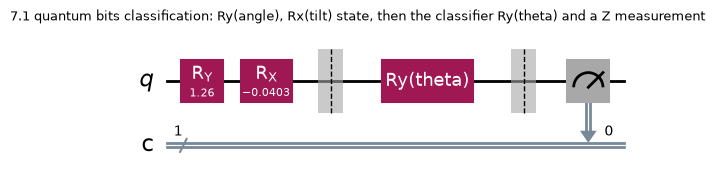

7.2 quantum phase recognition: 6-qubit QCNN (ground state | U1 U2 V1 U3 V2 F | H | measure)
   qubits = 6, depth of the flat classifier circuit = 8, independent trainable parameters = 66


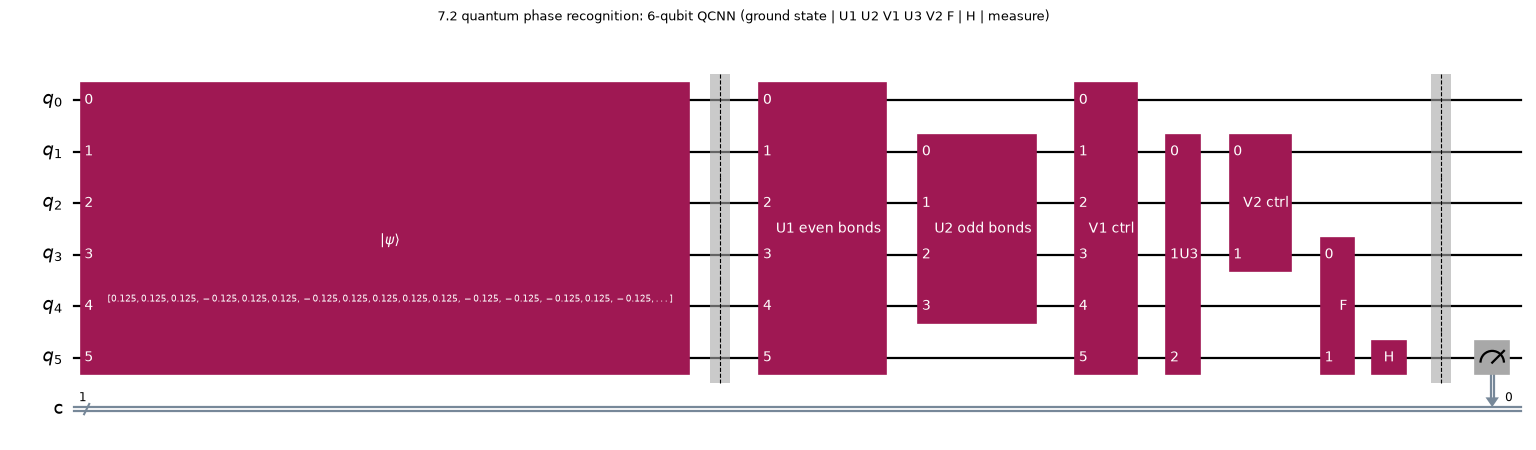

7.3 cluster excitation detection: cluster state + Rx(theta) on one qubit | QCNN | Z measurement
   qubits = 6, depth of the flat classifier circuit = 75, independent trainable parameters = 63


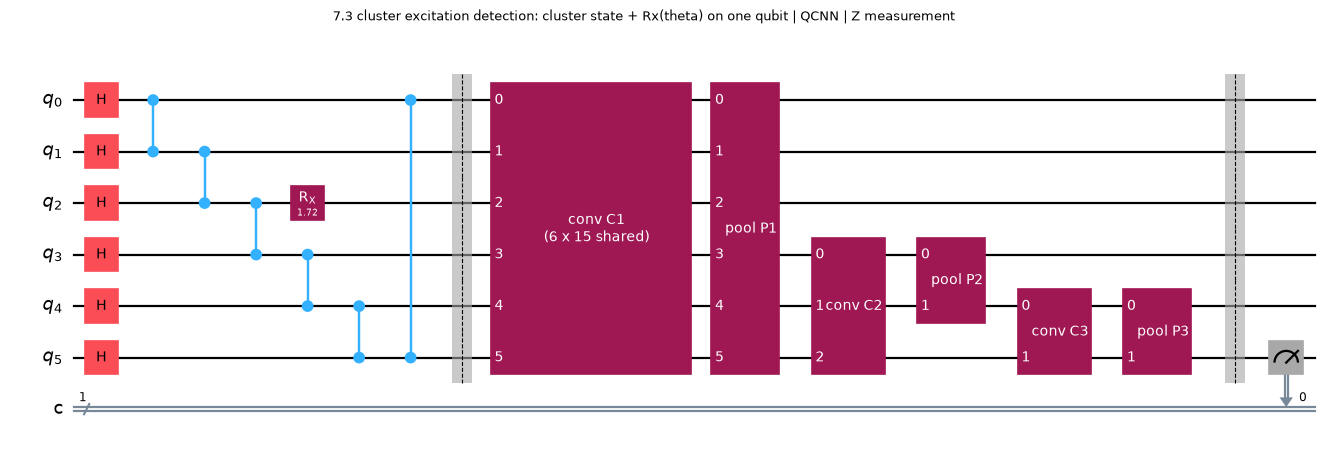

7.4 MNIST 3 vs 6: amplitude encoding on 8 qubits | QCNN | H, measure (|+>,|-> basis)
   qubits = 8, depth of the flat classifier circuit = 76, independent trainable parameters = 63


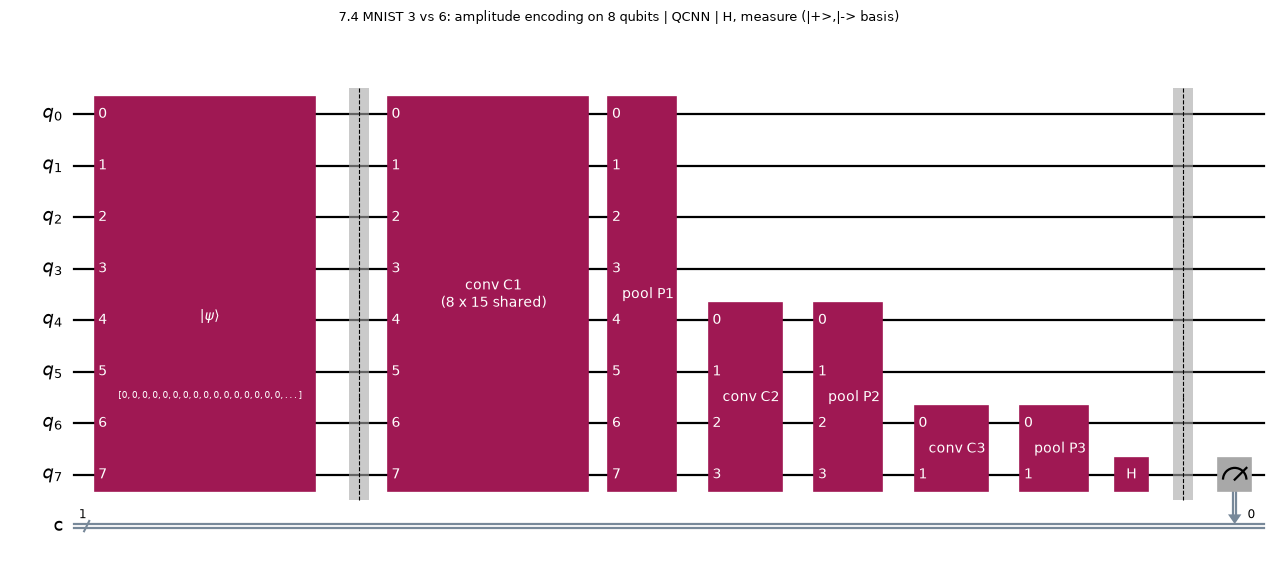

convolution block C (two_qubit_unitary, 15 shared parameters) and pooling block P (two_qubit_pool, 6 shared parameters), trained cluster model:


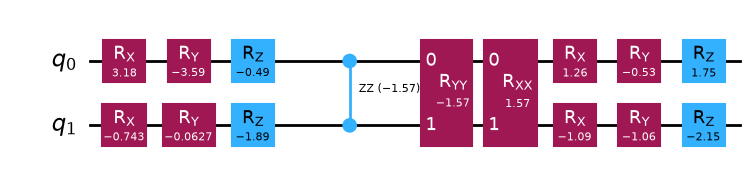

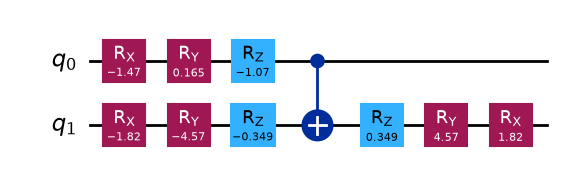

flat executed classifier circuit of the qpr model, depth 8:


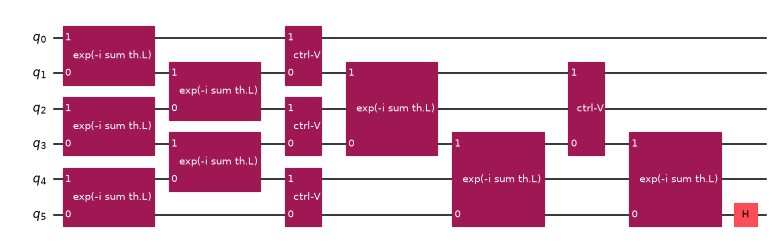

flat executed classifier circuit of the cluster model, depth 75:


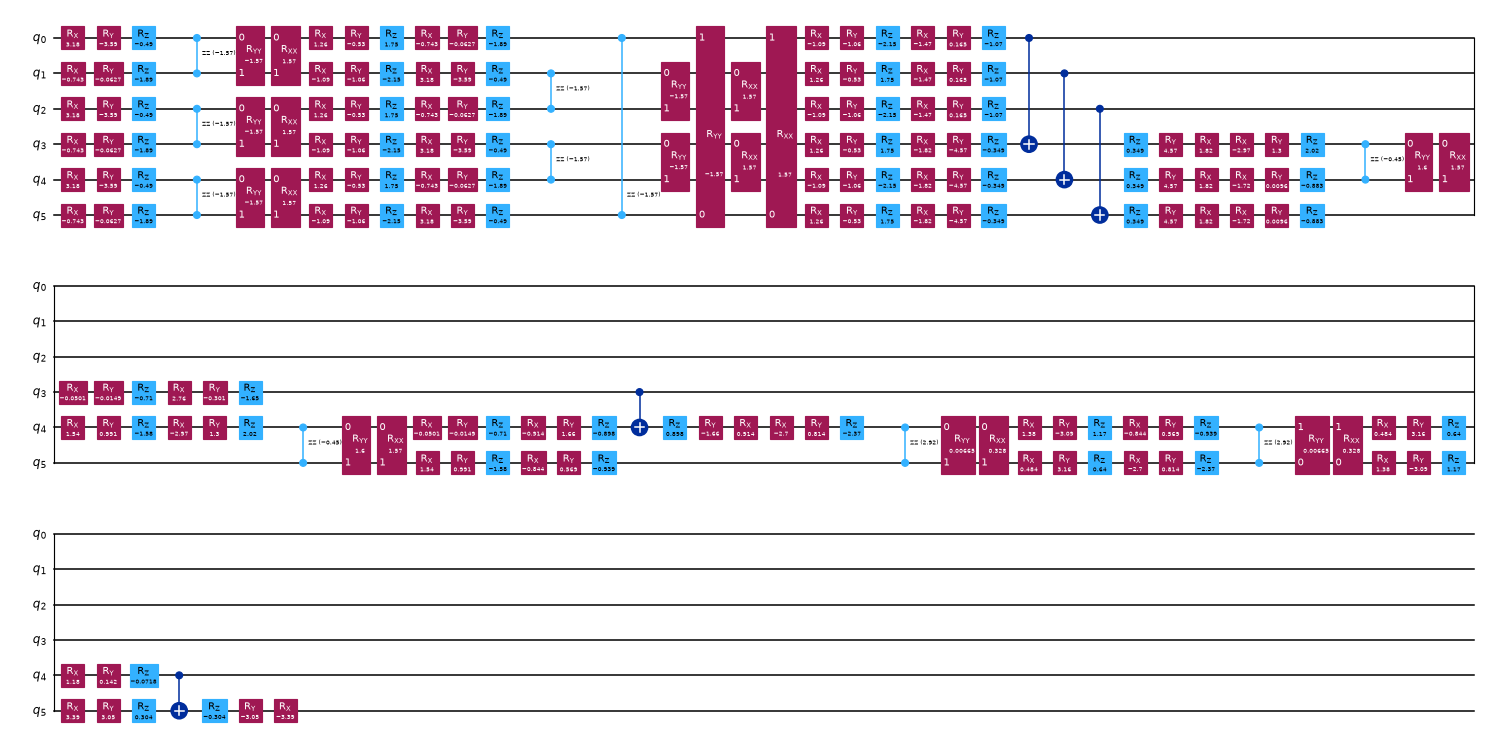

flat executed classifier circuit of the mnist model, depth 76:


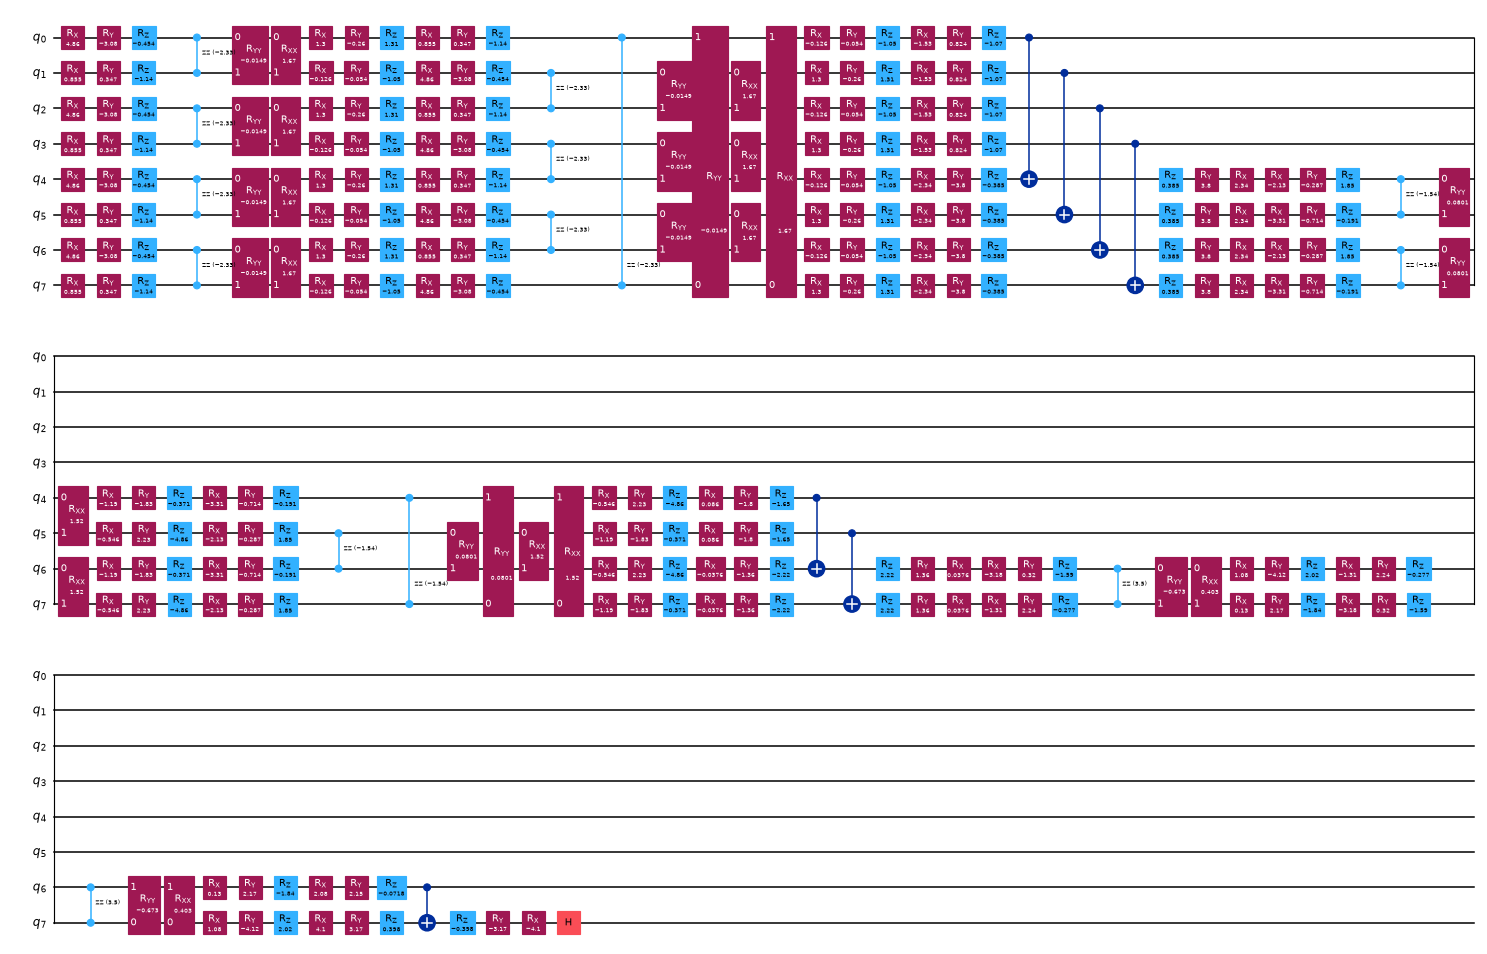

In [17]:
from IPython.display import display
# Draw the circuits that are executed: data preparation | trained classifier (one labelled box per layer) | measurement of the readout qubit.
for task, title in (("qubit", "7.1 quantum bits classification: Ry(angle), Rx(tilt) state, then the classifier Ry(theta) and a Z measurement"),
                    ("qpr", "7.2 quantum phase recognition: 6-qubit QCNN (ground state | U1 U2 V1 U3 V2 F | H | measure)"),
                    ("cluster", "7.3 cluster excitation detection: cluster state + Rx(theta) on one qubit | QCNN | Z measurement"),
                    ("mnist", "7.4 MNIST 3 vs 6: amplitude encoding on 8 qubits | QCNN | H, measure (|+>,|-> basis)")):
    m = RUN[(task, SEED)]["model"]
    full = full_circuit(PREP[task], QK[task]["hier"], m.readout, measure=True)
    print(f"{title}\n   qubits = {m.n}, depth of the flat classifier circuit = {QK[task]['flat'].depth()}, independent trainable parameters = {m.n_params}")
    fig = full.draw("mpl", fold=-1, scale=0.8 if m.n > 1 else 1.0)
    fig.suptitle(title, fontsize=9)
    display(fig)
# One convolution block and one pooling block of the TFQ QCNN, expanded into the gates that are actually run (15 and 6 parameters)
pk = RUN[("cluster", SEED)]["theta"]
blk = QuantumCircuit(2); qk_op(blk, "u2q", pk[0:15], (0, 1), None)
pool = QuantumCircuit(2); qk_op(pool, "pool2", pk[15:21], (0, 1), None)
print("convolution block C (two_qubit_unitary, 15 shared parameters) and pooling block P (two_qubit_pool, 6 shared parameters), trained cluster model:")
display(blk.draw("mpl", fold=-1))
display(pool.draw("mpl", fold=-1))
# The flat circuits (every elementary gate that is executed). The QPR boxes are the exponentials exp(-i sum theta_j Lambda_j) as 4 x 4 unitaries.
for task in ("qpr", "cluster", "mnist"):
    print(f"flat executed classifier circuit of the {task} model, depth {QK[task]['flat'].depth()}:")
    display(QK[task]["flat"].draw("mpl", fold=40, scale=0.55))

## Part 5. Robustness verification (Section 7.5, Tables 1 to 4)

For each classifier the effects `A_0, A_1` are extracted from the trained unitary, and for every training state

* `delta` = the exact optimal robust bound (Theorem 2 via `DualSDP`),
* the Lemma 1 radius `margin^2 / 2`.

Then, for the paper's four values of `eps`, the following columns are printed (they mirror Tables 1 to 4):

* `RA_lemma`: Algorithm 3, robust accuracy under-approximated with Lemma 1 only (`1 - r/|T|`);
* `RA_alg2`: Algorithm 2 exactly as written (`1 - |R|/|T|`, `|T|` = all training states, so a *misclassified* state with a large output margin is skipped by Lemma 1's test and counts as robust);
* `left_after_lemma` / `non_robust_alg2`: the numbers of states that Lemma 1 cannot certify and that Algorithm 2 then proves non-robust (the paper's "95 left, 80 non-robust" for the qubit task at `eps = 0.001`);
* `RA_correct_*`: the Section 4 definition (only correctly classified states count) from Lemma 1 and from the exact radius;
* `t_alg3`, `t_alg2`: wall-clock seconds on this machine (Algorithm 2 includes factorising the operators `A_l - A_k`, once per call).

In [18]:
# ---------------------------------------------------------------------------------------------
# Part 5: robustness verification of the four trained classifiers (Algorithms 1, 2 and 3 of the paper).
# ---------------------------------------------------------------------------------------------
VER = {}

def verify_run(task, seed):
    r = RUN[(task, seed)]
    tr = get_datasets(seed)[task][0]
    PSI, y = tr[0], tr[1]
    A = r["model"].effects(r["theta"])                       # Heisenberg effects A_0, A_1 of the trained circuit
    P = class_probs(PSI, A)
    assert np.allclose(P, outcome_probs_np(r["model"], r["theta"], PSI), atol=1e-9), "effects must reproduce the simulator's probabilities"
    sv = build_solvers(A)
    t0 = time.perf_counter()
    delta = np.array([sv[(int(l), 1 - int(l))].radius(psi) for psi, l in zip(PSI, y)])          # Theorem 2 for every training state
    t_every = time.perf_counter() - t0
    dL = lemma_radius(P)                                     # Lemma 1 radius for every training state
    correct = P.argmax(1) == y
    rows = []
    for eps in EPS[task]:
        t0 = time.perf_counter(); URA, cand = algorithm3_under_approx(class_probs(PSI, A), eps); t3 = time.perf_counter() - t0
        t0 = time.perf_counter(); sv2 = build_solvers(A); RA, R, ncand = algorithm2_robustness_verifier(PSI, y, sv2, A, eps); t2 = time.perf_counter() - t0
        rows.append(dict(eps=eps, RA_lemma=100 * URA, RA_alg2=100 * RA, left_after_lemma=int(cand.sum()), non_robust_alg2=len(R), t_alg3=t3, t_alg2=t2,
                         RA_correct_lemma=100 * robust_accuracy_correct_only(P, y, dL, eps), RA_correct_exact=100 * robust_accuracy_correct_only(P, y, delta, eps)))
    return dict(A=A, P=P, y=y, PSI=PSI, delta=delta, dL=dL, correct=correct, table=pd.DataFrame(rows), t_every=t_every, solvers=sv)

for sd in SEEDS:
    for task in MODEL_BUILDERS:
        VER[(task, sd)] = verify_run(task, sd)

pd.set_option("display.width", 200)
for task in MODEL_BUILDERS:
    v = VER[(task, SEED)]
    print(f"\n=== {task} (seed {SEED}): {len(v['y'])} training states, {int(v['correct'].sum())} correctly classified, exact radius of all states in {v['t_every']:.2f}s ===")
    print(v["table"].round(4).to_string(index=False))


=== qubit (seed 42): 800 training states, 800 correctly classified, exact radius of all states in 15.79s ===
  eps  RA_lemma  RA_alg2  left_after_lemma  non_robust_alg2  t_alg3  t_alg2  RA_correct_lemma  RA_correct_exact
0.001   100.000  100.000                 0                0  0.0003  0.0003           100.000           100.000
0.002    78.250   78.250               174              174  0.0002  3.4820            78.250            78.250
0.003    56.500   56.500               348              348  0.0005  8.1928            56.500            56.500
0.004    36.875   36.875               505              505  0.0005 12.1783            36.875            36.875

=== qpr (seed 42): 1000 training states, 778 correctly classified, exact radius of all states in 22.66s ===
   eps  RA_lemma  RA_alg2  left_after_lemma  non_robust_alg2  t_alg3  t_alg2  RA_correct_lemma  RA_correct_exact
0.0001      97.8     97.8                22               22  0.0053  0.4009           98.5861           98.

### Independent checks of the exact radius on the trained classifiers

The exact radius is only useful if it is right. Four checks on the real trained classifiers: (a) **Lemma 1 against Theorem 2**: the exact radius must never be smaller than Lemma 1's; for unitary circuits with a projective one-qubit measurement the two are expected to be *equal* (see the derivation in Part 1); (b) the SDP dual equals the pure-state QCQP solver; (c) the optimiser returned by Algorithm 1 sits exactly on the decision boundary at distance `delta`; (d) for the single-qubit classifier a brute-force search over a fine grid of the whole Bloch sphere (no theory at all) cannot find a closer misclassified state.

In [19]:
# ---------------------------------------------------------------------------------------------
# Independent checks of the exact radius on the real trained classifiers (seed SEED):
#  (a) Lemma 1 against Theorem 2 (the paper's Table 1-4 contrast between its two rows),
#  (b) the SDP dual against the pure-state QCQP (trust-region) solver,
#  (c) the primal optimiser returned by the dual: a state at distance delta that sits exactly on the decision boundary,
#  (d) for the single-qubit task, a brute-force search over the whole Bloch sphere that uses no theory at all.
# ---------------------------------------------------------------------------------------------
rng_x = np.random.default_rng(SEED)
rows = []
for task in MODEL_BUILDERS:
    v = VER[(task, SEED)]
    ok = np.where(v["correct"])[0]
    gap_all = v["delta"][ok] - v["dL"][ok]
    order = ok[np.argsort(v["delta"][ok])]
    idx = np.concatenate([order[: N_CROSSCHECK // 2], rng_x.choice(ok, N_CROSSCHECK // 2, replace=False)])       # the most fragile states + random ones
    d_qc, tie, dist_err = [], [], []
    for i in idx:
        l = int(v["y"][i]); k = 1 - l
        Wc = v["A"][l] - v["A"][k]
        d_qc.append(PureAdversary(v["PSI"][i], Wc).radius())
        dk, sig = v["solvers"][(l, k)].radius(v["PSI"][i], return_state=True)
        pp = class_probs(sig[None], v["A"])[0]
        tie.append(abs(pp[l] - pp[k])); dist_err.append(abs((1 - abs(np.vdot(v["PSI"][i], sig)) ** 2) - dk))
    rows.append(dict(task=task, correct_states=len(ok), max_abs_exact_minus_lemma=float(np.max(np.abs(gap_all))), min_exact_minus_lemma=float(gap_all.min()),
                     checked=len(idx), max_abs_dual_minus_qcqp=float(np.max(np.abs(np.array(d_qc) - v["delta"][idx]))),
                     max_tie_violation=float(np.max(tie)), max_distance_error=float(np.max(dist_err))))
XC = pd.DataFrame(rows)
print(XC.to_string(index=False))
assert (XC.min_exact_minus_lemma > -1e-9).all()
assert (XC.max_abs_dual_minus_qcqp < 1e-8).all() and (XC.max_tie_violation < 1e-7).all() and (XC.max_distance_error < 1e-8).all()
print("OK on all four classifiers: the exact radius never falls below Lemma 1, equals the pure-state QCQP and its optimiser lies on the decision boundary")

# (d) brute force on the Bloch sphere for the qubit classifier: smallest infidelity of any pure state that the classifier assigns to the other class
v = VER[("qubit", SEED)]
tt, pp_ = np.meshgrid(np.linspace(0, PI, 721), np.linspace(0, 2 * PI, 1441), indexing="ij")
grid = np.stack([np.cos(tt / 2), np.sin(tt / 2) * np.exp(1j * pp_)], -1).reshape(-1, 2)
Pgrid = class_probs(grid, v["A"]); lab_grid = Pgrid.argmax(1)
ok = np.where(v["correct"])[0][:60]
bf = []
for i in ok:
    other = lab_grid != int(v["y"][i])
    inf = 1 - np.abs(grid[other] @ v["PSI"][i].conj()) ** 2
    bf.append(inf.min())
bf = np.array(bf)
print(f"qubit task, {len(ok)} states: brute-force minimum infidelity on a 721 x 1441 Bloch grid is >= exact radius for all states: {bool(np.all(bf >= v['delta'][ok] - 1e-12))};"
      f" median ratio brute-force/exact = {np.median(bf / v['delta'][ok]):.5f}, max = {np.max(bf / v['delta'][ok]):.5f}")
assert np.all(bf >= v["delta"][ok] - 1e-12)

   task  correct_states  max_abs_exact_minus_lemma  min_exact_minus_lemma  checked  max_abs_dual_minus_qcqp  max_tie_violation  max_distance_error
  qubit             800               6.726390e-16          -4.399692e-16       60             5.969617e-16       4.996004e-16        8.881784e-16
    qpr             778               2.654127e-15          -2.654127e-15       60             1.946360e-15       6.661338e-16        5.551115e-16
cluster             838               3.996803e-15          -3.996803e-15       60             4.024558e-16       1.554312e-15        7.771561e-16
  mnist             974               6.800116e-16          -4.371503e-16       60             4.159000e-16       1.332268e-15        8.881784e-16
OK on all four classifiers: the exact radius never falls below Lemma 1, equals the pure-state QCQP and its optimiser lies on the decision boundary


qubit task, 60 states: brute-force minimum infidelity on a 721 x 1441 Bloch grid is >= exact radius for all states: True; median ratio brute-force/exact = 1.03763, max = 1.07047


### Sensitivity of the single-qubit numbers to the unspecified spread of the data

The paper says only that the samples are drawn "around" the two Bloch vectors; the recipe used here (the TensorFlow Quantum formula `b = |theta_a - theta_b| / 5 = 0.046`) leaves a gap of about 0.14 rad between the two clouds, so no state is closer than about 0.06 rad to the decision boundary and the robust accuracy is 100% at `eps = 0.001`. The next cell repeats the experiment (new data, new training, robust accuracy from the exact radius, which equals Lemma 1) for wider uniform clouds to show how strongly Table 1 depends on this unspecified choice. It is a diagnostic only; the numbers of the main comparison keep the TensorFlow Quantum recipe.

In [20]:
def qubit_data_with_spread(seed, blob, n_total=1000, theta_a=1.0, theta_b=1.23):
    rng = np.random.default_rng(seed)
    lab = (rng.random(n_total) >= 0.5).astype(int)
    sx = rng.uniform(-blob, blob, n_total); sy = rng.uniform(-blob, blob, n_total)
    ang = np.where(lab == 0, theta_a, theta_b) + sy
    psi = np.zeros((n_total, 2), complex)
    for i in range(n_total):
        v = np.array([math.cos(ang[i] / 2), math.sin(ang[i] / 2)], complex)
        rx = np.array([[math.cos(sx[i] / 2), -1j * math.sin(sx[i] / 2)], [-1j * math.sin(sx[i] / 2), math.cos(sx[i] / 2)]])
        psi[i] = rx @ v
    return psi, lab

rows = []
for blob in (0.046, 0.06, 0.08, 0.10):
    psi_s, lab_s = qubit_data_with_spread(SEED, blob)
    m_s = model_qubit()
    th_s, _ = train_model(m_s, psi_s[:800], lab_s[:800], 200, LR["qubit"], INIT_SCALE["qubit"], SEED, 2)
    A_s = m_s.effects(th_s); P_s = class_probs(psi_s[:800], A_s); dL_s = lemma_radius(P_s)
    rows.append(dict(spread_b=blob, theta=round(float(th_s[0]), 4), train_acc=100 * float((P_s.argmax(1) == lab_s[:800]).mean()),
                     **{f"RA(eps={e:g})": round(100 * float(np.mean(dL_s > e)), 2) for e in EPS["qubit"]}))
rows.append(dict(spread_b="paper (Table 1, Lemma 1 row)", theta=0.4835, train_acc=100.0, **{f"RA(eps={e:g})": v_ for e, v_ in zip(EPS["qubit"], PAPER["qubit"]["lemma"])}))
print(pd.DataFrame(rows).to_string(index=False))

                    spread_b  theta  train_acc  RA(eps=0.001)  RA(eps=0.002)  RA(eps=0.003)  RA(eps=0.004)
                       0.046 0.4558      100.0         100.00          78.25          56.50          36.88
                        0.06 0.4557      100.0          92.88          70.75          55.00          40.12
                        0.08 0.4556      100.0          82.50          66.38          53.12          42.38
                         0.1 0.4554      100.0          76.50          63.62          52.00          43.50
paper (Table 1, Lemma 1 row) 0.4835      100.0          88.13          75.88          58.88          38.25


## Part 6. Gradient attacks against the certified radius, and executing the adversarial examples

**Attacks.** For correctly classified training states (the most fragile ones plus random ones) projected gradient descent on the fidelity sphere (`pgd_attack`, two restarts, the first one starting along the gradient of the margin as in FGSM) tries to find a misclassified state at fidelity distance `eps`. Three questions: does an attack ever succeed below the certified radius (it must not: `attack_beats_bound` must be 0), does it succeed just above it (`1.01 x radius`), and how large is the smallest `eps` at which it succeeds relative to the exact radius (a tightness measure; 1 means the certificate cannot be improved)? A random-noise attack of the same size is added for contrast.

   task  states  attack_beats_bound pgd_success_at_1p01_delta random_noise_success_at_1p01_delta  median_eps_pgd_over_exact  max_eps_pgd_over_exact
  qubit      60                   0                     60/60                              60/60                   1.000977                1.000977
    qpr      60                   0                     60/60                               0/60                   1.000977                1.000977
cluster      60                   0                     60/60                               0/60                   1.000977                1.000977
  mnist      60                   0                     60/60                               0/60                   1.000977                1.000977
OK: no gradient attack ever succeeded below the verified radius


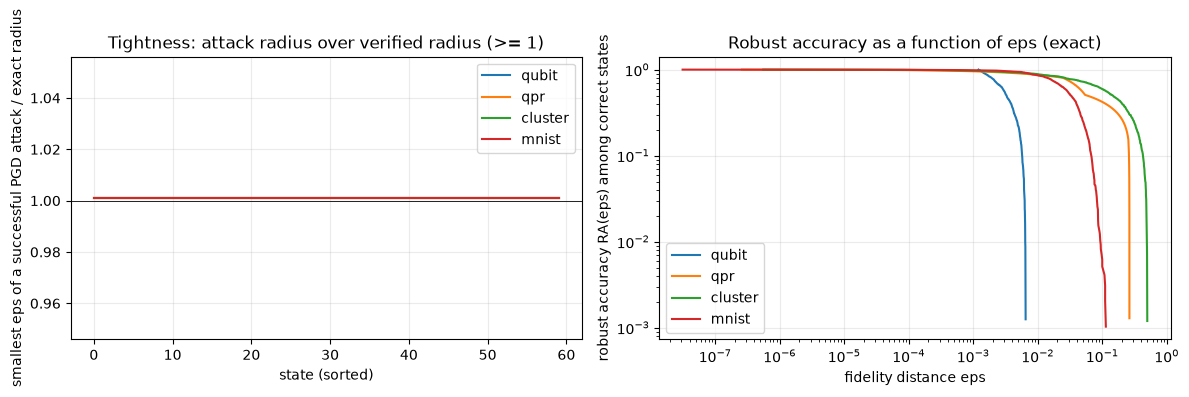

In [21]:
# ---------------------------------------------------------------------------------------------
# Part 6: gradient attacks against the certified radius. The verified radius must never be beaten by an attack; the gap measures tightness.
# ---------------------------------------------------------------------------------------------
def attack_success(psi, Wc, eps, rng, steps=60, restarts=1):
    return pgd_attack(psi, Wc, eps, rng, steps=steps, restarts=restarts) < 0

def random_noise_success(psi, Wc, eps, rng, n_try=200):
    a, b = math.sqrt(1 - eps), math.sqrt(eps)
    for _ in range(n_try):
        phi = rng.normal(size=len(psi)) + 1j * rng.normal(size=len(psi)); phi -= psi * (psi.conj() @ phi); phi /= np.linalg.norm(phi)
        u = a * psi + b * phi
        if (u.conj() @ Wc @ u).real < 0:
            return True
    return False

rng_a = np.random.default_rng(SEED + 7)
rows, ATT = [], {}
for task in MODEL_BUILDERS:
    v = VER[(task, SEED)]
    ok = np.where(v["correct"])[0]
    order = ok[np.argsort(v["delta"][ok])]
    idx = np.concatenate([order[: N_ATTACK // 2], rng_a.choice(ok, N_ATTACK // 2, replace=False)])
    viol = succ_above = rand_above = 0
    ratios = []
    for i in idx:
        l = int(v["y"][i]); Wc = v["A"][l] - v["A"][1 - l]; psi = v["PSI"][i]; d = v["delta"][i]
        viol += attack_success(psi, Wc, 0.999 * d, rng_a)            # must never succeed below the certified radius
        succ_above += attack_success(psi, Wc, 1.01 * d, rng_a)
        rand_above += random_noise_success(psi, Wc, 1.01 * d, rng_a)
        lo, hi = d, 1.5 * d                                          # smallest eps at which the gradient attack succeeds (bisection)
        if not attack_success(psi, Wc, hi, rng_a):
            hi = min(0.9, 4 * d)
        for _ in range(9):
            mid = 0.5 * (lo + hi)
            if attack_success(psi, Wc, mid, rng_a): hi = mid
            else: lo = mid
        ratios.append(hi / d)
    ATT[task] = np.array(ratios)
    rows.append(dict(task=task, states=len(idx), attack_beats_bound=int(viol), pgd_success_at_1p01_delta=f"{succ_above}/{len(idx)}",
                     random_noise_success_at_1p01_delta=f"{rand_above}/{len(idx)}", median_eps_pgd_over_exact=float(np.median(ratios)), max_eps_pgd_over_exact=float(np.max(ratios))))
ATTACK_TABLE = pd.DataFrame(rows)
print(ATTACK_TABLE.to_string(index=False))
assert (ATTACK_TABLE.attack_beats_bound == 0).all(), "a verified radius was violated by an attack"
print("OK: no gradient attack ever succeeded below the verified radius")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for task in MODEL_BUILDERS:
    ax[0].plot(np.sort(ATT[task]), label=task)
ax[0].axhline(1, color="k", lw=0.6); ax[0].set_xlabel("state (sorted)"); ax[0].set_ylabel("smallest eps of a successful PGD attack / exact radius")
ax[0].set_title("Tightness: attack radius over verified radius (>= 1)"); ax[0].legend()
for task in MODEL_BUILDERS:
    v = VER[(task, SEED)]; ok = v["correct"]
    ax[1].loglog(np.sort(v["delta"][ok]), 1 - np.arange(ok.sum()) / ok.sum(), label=task)
ax[1].set_xlabel("fidelity distance eps"); ax[1].set_ylabel("robust accuracy RA(eps) among correct states"); ax[1].set_title("Robust accuracy as a function of eps (exact)"); ax[1].legend()
plt.tight_layout(); plt.show()

### Executing the adversarial examples on the Qiskit circuits

Algorithm 2 returns the states that are **not** `eps`-robust at the largest `eps` of each table. For each of them (up to the budget in the configuration) the worst-case state inside the fidelity ball is built (`PureAdversary.state`) and **run through the Qiskit circuit**, not through the simulator that found it. We check that the label flips, that the state is inside the ball, and that the optimiser returned by Algorithm 1 lies on the decision boundary at distance `delta`.

In [22]:
# ---------------------------------------------------------------------------------------------
# Adversarial examples found by the verification are re-executed through the Qiskit circuits (not the simulator that found them).
# ---------------------------------------------------------------------------------------------
rows, EXEC = [], {}
for task in MODEL_BUILDERS:
    v = VER[(task, SEED)]; m = RUN[(task, SEED)]["model"]; clf = QK[task]["flat"]
    eps = EPS[task][-1]
    bad = np.where(v["correct"] & (v["delta"] <= eps))[0]            # states that Algorithm 2 reports as NOT eps-robust at the largest eps
    n_bad = len(bad)
    if n_bad == 0:                                                    # fall back to the most fragile states with eps just above their radius
        bad = np.where(v["correct"])[0][np.argsort(v["delta"][v["correct"]])][:N_EXECUTE]
    pick = bad[:N_EXECUTE]
    flips = dist_ok = tie_ok = 0
    for i in pick:
        l = int(v["y"][i]); psi = v["PSI"][i]; d = v["delta"][i]
        e = eps if n_bad else 1.001 * d
        Wc = v["A"][l] - v["A"][1 - l]
        u = PureAdversary(psi, Wc).state(e)                           # worst-case state inside the fidelity ball of radius e
        pq = Statevector(u).evolve(clf).probabilities([m.readout])    # executed on the Qiskit circuit
        flips += int(np.argmax(pq) != l)
        dist_ok += int(1 - abs(np.vdot(psi, u)) ** 2 <= e + 1e-12)
        _, sig = v["solvers"][(l, 1 - l)].radius(psi, return_state=True)   # the optimiser returned by Algorithm 1 (on the boundary)
        pt = Statevector(sig).evolve(clf).probabilities([m.readout])
        tie_ok += int(abs(pt[l] - pt[1 - l]) < 1e-7 and abs((1 - abs(np.vdot(psi, sig)) ** 2) - d) < 1e-8)
    EXEC[task] = (pick, eps if n_bad else None)
    rows.append(dict(task=task, eps=eps, non_robust_states=n_bad, executed=len(pick), label_flipped_on_qiskit=f"{flips}/{len(pick)}",
                     within_fidelity_ball=f"{dist_ok}/{len(pick)}", algorithm1_optimiser_on_boundary=f"{tie_ok}/{len(pick)}"))
EXEC_TABLE = pd.DataFrame(rows)
print(EXEC_TABLE.to_string(index=False))
assert all(int(s.split("/")[0]) == int(s.split("/")[1]) for s in EXEC_TABLE.label_flipped_on_qiskit)
assert all(int(s.split("/")[0]) == int(s.split("/")[1]) for s in EXEC_TABLE.within_fidelity_ball)
print("OK: every adversarial example flips the label on the Qiskit circuit while staying inside the fidelity ball")

   task    eps  non_robust_states  executed label_flipped_on_qiskit within_fidelity_ball algorithm1_optimiser_on_boundary
  qubit 0.0040                505        40                   40/40                40/40                            40/40
    qpr 0.0004                 22        22                   22/22                22/22                            22/22
cluster 0.0004                 14        14                   14/14                14/14                            14/14
  mnist 0.0004                 10        10                   10/10                10/10                            10/10
OK: every adversarial example flips the label on the Qiskit circuit while staying inside the fidelity ball


### Re-drawing Fig. 3: benign and adversarial MNIST images

Fig. 3 of the paper shows two MNIST states, their 16 x 16 versions, the adversarial images decoded from the adversarial states, and their difference. A natural image has real, non-negative amplitudes, so the adversarial state is also computed with the QCQP restricted to **real** perturbations (this can only make the radius larger than the complex one). For each digit the notebook takes, among the 12 least robust correctly classified training images, the one with the smallest real radius, builds the worst-case real state at 1.0001 times that radius, decodes it back to pixels (multiplying by the image norm) and executes it on the Qiskit circuit.

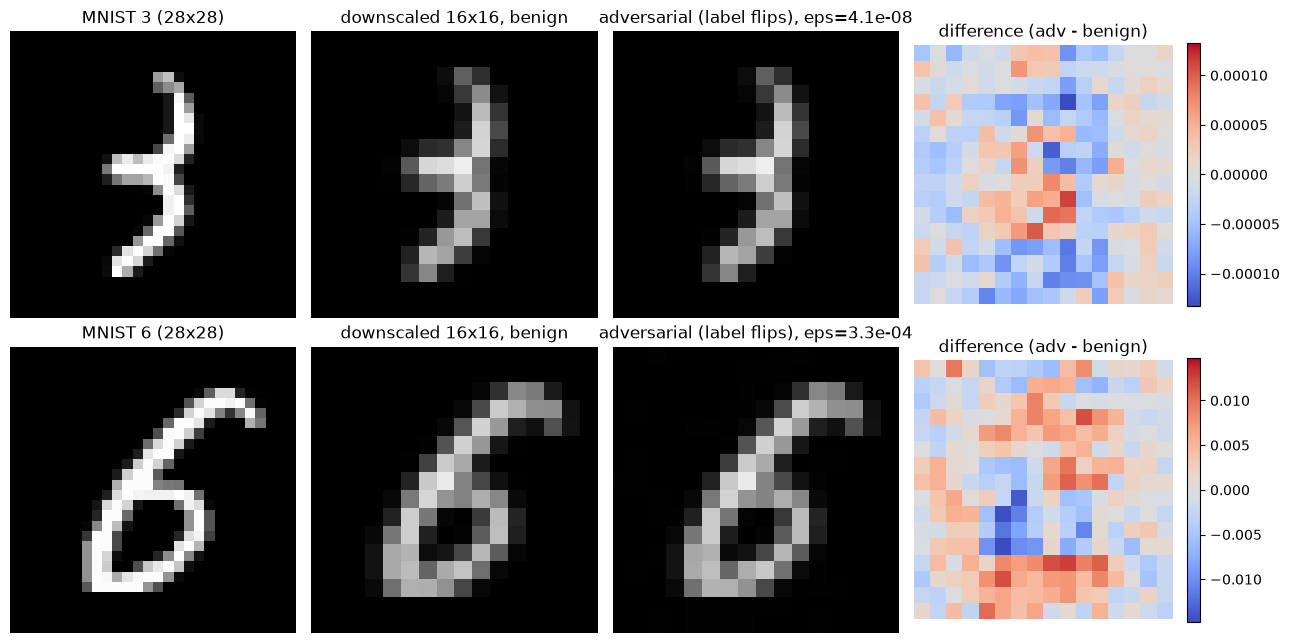

 digit  true_label  p_true_before  p_true_after  label_after  fidelity_distance  complex_radius  real_radius  max_pixel_change
     3           1       0.500177      0.500000            0           0.000000        0.000000     0.000000          0.000133
     6           0       0.515918      0.499999            1           0.000335        0.000253     0.000335          0.014738


In [23]:
# ---------------------------------------------------------------------------------------------
# Re-drawing Fig. 3: benign MNIST states and their adversarial examples. A natural image has real amplitudes, so we also solve the
# QCQP restricted to REAL perturbations (replace Wc by Re Wc and psi by a real vector): the adversarial state is then again a real 16 x 16 image.
# ---------------------------------------------------------------------------------------------
v = VER[("mnist", SEED)]; m = RUN[("mnist", SEED)]["model"]; clf = QK["mnist"]["flat"]
ex = get_datasets(SEED)["mnist"][0][2]
def real_radius(i):
    l = int(v["y"][i]); Wr = (v["A"][l] - v["A"][1 - l]).real.astype(complex)
    return PureAdversary(v["PSI"][i].real.astype(complex), Wr).radius()

pool_idx = {}
for dgt in (3, 6):
    cand = np.where(v["correct"] & (ex["digit"] == dgt))[0]
    cand = cand[np.argsort(v["delta"][cand])][:12]
    rr = np.array([real_radius(i) for i in cand])
    pool_idx[dgt] = (cand[int(np.argmin(rr))], float(rr.min()))

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
MN_ROWS = []
for r_, dgt in enumerate((3, 6)):
    i, rad = pool_idx[dgt]
    l = int(v["y"][i]); psi = v["PSI"][i].real
    Wr = (v["A"][l] - v["A"][1 - l]).real.astype(complex)
    u = PureAdversary(psi.astype(complex), Wr).state(1.0001 * rad)
    u = u * np.sign((psi @ u).real)                                    # fix the global sign (F = |<psi|u>|^2 does not see it)
    assert np.abs(u.imag).max() < 1e-9
    u = u.real
    pq = Statevector(u.astype(complex)).evolve(clf).probabilities([m.readout])          # executed on the Qiskit circuit
    img0 = ex["img16"][i]; scale = ex["norm"][i]
    adv = (u * scale).reshape(16, 16)
    diff = adv - img0
    MN_ROWS.append(dict(digit=dgt, true_label=l, p_true_before=float(v["P"][i][l]), p_true_after=float(pq[l]), label_after=int(np.argmax(pq)),
                        fidelity_distance=float(1 - (psi @ u) ** 2), complex_radius=float(v["delta"][i]), real_radius=rad, max_pixel_change=float(np.abs(diff).max())))
    axes[r_, 0].imshow(ex["img28"][i], cmap="gray"); axes[r_, 0].set_title(f"MNIST {dgt} (28x28)")
    axes[r_, 1].imshow(img0, cmap="gray", vmin=0, vmax=1); axes[r_, 1].set_title("downscaled 16x16, benign")
    axes[r_, 2].imshow(adv, cmap="gray", vmin=0, vmax=1); axes[r_, 2].set_title(f"adversarial (label flips), eps={MN_ROWS[-1]['fidelity_distance']:.1e}")
    im = axes[r_, 3].imshow(diff, cmap="coolwarm", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max()); axes[r_, 3].set_title("difference (adv - benign)"); plt.colorbar(im, ax=axes[r_, 3], fraction=0.046)
    for a in axes[r_]: a.axis("off")
plt.tight_layout(); plt.show()
print(pd.DataFrame(MN_ROWS).round(6).to_string(index=False))
assert all(r_["label_after"] != r_["true_label"] for r_ in MN_ROWS)

## Part 7. Classical baselines on the same inputs

The paper compares with classical verification only in words. As required for every notebook here, classical models are trained on **exactly the same inputs** (the real and imaginary parts of the state vectors) and scored on the same splits: logistic regression, an RBF-kernel SVC and a random forest, with fixed hyper-parameters (no tuning on validation data). For MNIST there is also a classical classifier whose adversarial radius is known **in closed form in the same fidelity metric**: a homogeneous linear classifier `sign(w.x)` on the unit-norm pixel vectors. Its closest adversarial unit vector lies on the hyperplane `w.x' = 0`, so the fidelity radius is `(w.x)^2 / ||w||^2`; its robust accuracy at the paper's four `eps` can be put next to the QCNN's.

In [24]:
# ---------------------------------------------------------------------------------------------
# Part 7: classical baselines on exactly the same inputs (real and imaginary parts of the state vector), fitted on the training split only.
# ---------------------------------------------------------------------------------------------
def state_features(psi):
    return np.hstack([psi.real, psi.imag]) if np.abs(psi.imag).max() > 1e-12 else psi.real

rows = []
for task in MODEL_BUILDERS:
    tr, va = get_datasets(SEED)[task]
    Xtr, Xva = state_features(tr[0]), state_features(va[0])
    clfs = {"logistic regression": LogisticRegression(max_iter=5000, C=10.0, random_state=SEED),          # CHOICE: fixed hyper-parameters, no tuning on validation data
            "SVC (rbf, C=10)": SVC(kernel="rbf", C=10.0, gamma="scale", random_state=SEED),
            "random forest (200)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)}
    for nm, c in clfs.items():
        c.fit(Xtr, tr[1])
        rows.append(dict(task=task, model=nm, train_acc=100 * c.score(Xtr, tr[1]), val_acc=100 * c.score(Xva, va[1])))
    r = RUN[(task, SEED)]
    rows.append(dict(task=task, model="QCNN (this paper's classifier)", train_acc=100 * r["acc_tr"], val_acc=100 * r["acc_va"]))
BASE = pd.DataFrame(rows)
print(BASE.round(2).to_string(index=False))

# A classical classifier whose adversarial radius is known in closed form, in the SAME fidelity metric: a homogeneous linear classifier
# sign(w.x) on the unit-norm MNIST pixel vectors. The closest unit vector on the hyperplane w.x' = 0 has overlap cos(phi) with sin(phi) = |w.x| / ||w||,
# hence the fidelity radius is (w.x)^2 / ||w||^2.
tr, va = get_datasets(SEED)["mnist"]
lin = LogisticRegression(fit_intercept=False, max_iter=5000, C=10.0, random_state=SEED).fit(tr[0].real, tr[1])
w = lin.coef_[0]
marg = tr[0].real @ w
ok_lin = (marg > 0) == (tr[1] == 1)
d_lin = (marg ** 2) / (w @ w)
v = VER[("mnist", SEED)]
cmp_rows = []
for eps in EPS["mnist"]:
    cmp_rows.append(dict(eps=f"{eps:g}", linear_classifier_RA_correct=100 * float(np.mean(d_lin[ok_lin] > eps)), QCNN_RA_correct_exact=100 * robust_accuracy_correct_only(v["P"], v["y"], v["delta"], eps)))
LIN = pd.DataFrame(cmp_rows)
print("\nMNIST 3 vs 6: homogeneous linear classifier on the same amplitude vectors (train acc %.1f%%, val acc %.1f%%), exact fidelity radius (w.x)^2/||w||^2" %
      (100 * lin.score(tr[0].real, tr[1]), 100 * lin.score(va[0].real, va[1])))
print(LIN.round(2).to_string(index=False))

   task                          model  train_acc  val_acc
  qubit            logistic regression     100.00   100.00
  qubit                SVC (rbf, C=10)     100.00   100.00
  qubit            random forest (200)     100.00   100.00
  qubit QCNN (this paper's classifier)     100.00   100.00
    qpr            logistic regression      99.60    98.25
    qpr                SVC (rbf, C=10)      99.80    68.00
    qpr            random forest (200)     100.00    98.75
    qpr QCNN (this paper's classifier)      77.80    61.00
cluster            logistic regression     100.00    99.72
cluster                SVC (rbf, C=10)      99.64    98.33
cluster            random forest (200)     100.00    99.72
cluster QCNN (this paper's classifier)      99.76    99.72
  mnist            logistic regression      99.70    99.00
  mnist                SVC (rbf, C=10)     100.00    99.50
  mnist            random forest (200)     100.00    99.00
  mnist QCNN (this paper's classifier)      97.40    96.

## Part 8. The paper's numbers next to ours

One row per checkable claim. Verdicts: **reproduced** (within 2 percentage points, or 0.02 for plain numbers such as the learned angle), **not reached** / **exceeded** (outside the tolerance, with the gap in the column `difference`), **cannot be checked** (absolute timings on other hardware and another SDP solver). Where several seeds were run the column `notebook` is their mean and `spread_over_seeds` their standard deviation. "Robust bound" rows come from Algorithm 3 (Lemma 1), "optimal bound" rows from Algorithm 2 run literally as in the paper.

In [25]:
# ---------------------------------------------------------------------------------------------
# Part 8: the paper's numbers next to ours, one verdict per claim (tolerance: 2 percentage points, 0.02 for plain numbers).
# ---------------------------------------------------------------------------------------------
def verdict(paper, ours, tol):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def mean_std(vals):
    vals = np.asarray(vals, float)
    return float(vals.mean()), float(vals.std())

claims = []
def add(task, name, paper, vals, tol, unit="%"):
    mu, sd = mean_std(vals)
    claims.append(dict(experiment=task, claim=name, paper=paper, notebook=round(mu, 4), spread_over_seeds=round(sd, 4), difference=round(mu - paper, 4),
                       verdict=verdict(paper, mu, tol)))

for task, P_ in PAPER.items():
    add(task, "training accuracy", P_["train"], [100 * RUN[(task, s)]["acc_tr"] for s in SEEDS], TOL_PTS)
    add(task, "validation accuracy", P_["val"], [100 * RUN[(task, s)]["acc_va"] for s in SEEDS], TOL_PTS)
    if task == "qubit":
        add(task, "learned angle theta of Ry(theta)", P_["theta"], [RUN[(task, s)]["theta"][0] for s in SEEDS], TOL_ABS, unit="rad")
    for j, eps in enumerate(EPS[task]):
        add(task, f"robust accuracy, robust bound (Lemma 1, Alg. 3), eps={eps:g}", P_["lemma"][j], [VER[(task, s)]["table"].RA_lemma[j] for s in SEEDS], TOL_PTS)
    for j, eps in enumerate(EPS[task]):
        add(task, f"robust accuracy, optimal bound (Theorem 2, Alg. 2), eps={eps:g}", P_["alg2"][j], [VER[(task, s)]["table"].RA_alg2[j] for s in SEEDS], TOL_PTS)
add("qubit", "states left after Lemma 1 at eps=0.001 (of 800)", PAPER["qubit"]["left"], [VER[("qubit", s)]["table"].left_after_lemma[0] for s in SEEDS], 0.02 * 800)
add("qubit", "states found non-robust by Alg. 2 at eps=0.001 (of 800)", PAPER["qubit"]["nonrobust"], [VER[("qubit", s)]["table"].non_robust_alg2[0] for s in SEEDS], 0.02 * 800)

# qualitative claims about the verification times (absolute seconds depend on the machine and the SDP solver, so they cannot be compared)
for task in PAPER:
    ts3 = np.mean([VER[(task, s)]["table"].t_alg3 for s in SEEDS], axis=0); ts2 = np.mean([VER[(task, s)]["table"].t_alg2 for s in SEEDS], axis=0)
    has_cand = np.mean([VER[(task, s)]["table"].left_after_lemma for s in SEEDS], axis=0) > 0          # at an eps with no candidate Algorithm 2 has nothing to do
    faster = bool(np.all(ts3[has_cand] < ts2[has_cand]))
    claims.append(dict(experiment=task, claim="Alg. 3 (Lemma 1) is faster than Alg. 2 at every eps (that has candidates)", paper="yes", notebook="yes" if faster else "no",
                       spread_over_seeds="", difference="", verdict="reproduced" if faster else "not reached"))
    claims.append(dict(experiment=task, claim="Alg. 2 time grows with eps while Alg. 3 stays flat", paper="yes",
                       notebook=f"t2: {ts2[0]:.3g}s -> {ts2[-1]:.3g}s; t3: {ts3.min():.2g}-{ts3.max():.2g}s",
                       spread_over_seeds="", difference="", verdict="reproduced" if (ts2[-1] > ts2[0] and ts3.max() < 5 * ts3.min() + 1e-3) else "not reached"))
    claims.append(dict(experiment=task, claim="absolute verification times (s)", paper=f"Alg.3 {PAPER[task]['t3'][0]}-{PAPER[task]['t3'][-1]}, Alg.2 {PAPER[task]['t2'][0]}-{PAPER[task]['t2'][-1]}",
                       notebook=f"Alg.3 {ts3.min():.3g}-{ts3.max():.3g}, Alg.2 {ts2.min():.3g}-{ts2.max():.3g}", spread_over_seeds="", difference="", verdict="cannot be checked (other machine, SDP solver)"))
# claim that is implicit in the paper: the optimal bound can only improve on Lemma 1
claims.append(dict(experiment="all", claim="exact (Theorem 2) robust accuracy >= Lemma 1 robust accuracy", paper="yes",
                   notebook="yes" if all((VER[(t, s)]["table"].RA_alg2 >= VER[(t, s)]["table"].RA_lemma - 1e-9).all() for t in PAPER for s in SEEDS) else "no",
                   spread_over_seeds="", difference="", verdict="reproduced" if all((VER[(t, s)]["table"].RA_alg2 >= VER[(t, s)]["table"].RA_lemma - 1e-9).all() for t in PAPER for s in SEEDS) else "not reached"))
claims.append(dict(experiment="all", claim="adversarial examples found are real and the bound is never violated by attacks", paper="yes (Fig. 3, Section 7.5)",
                   notebook=f"{int(ATTACK_TABLE.attack_beats_bound.sum())} attack successes below the radius; all {int(EXEC_TABLE.executed.sum())} re-executed examples flip the label",
                   spread_over_seeds="", difference="", verdict="reproduced" if ATTACK_TABLE.attack_beats_bound.sum() == 0 else "not reached"))
CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80)
print(CLAIMS.to_string(index=False))
print("\nVerdict counts:\n" + CLAIMS.verdict.value_counts().to_string())

experiment                                                                          claim                                    paper                                                                        notebook spread_over_seeds difference                                       verdict
     qubit                                                              training accuracy                                    100.0                                                                           100.0               0.0        0.0                                    reproduced
     qubit                                                            validation accuracy                                    100.0                                                                           100.0               0.0        0.0                                    reproduced
     qubit                                               learned angle theta of Ry(theta)                                   0.4835            

## Reading the paper critically

*(Numbers below refer to the committed run: `FAST_MODE = False`, three seeds, about 33 minutes on an 8-thread CPU. Tables above show seed 42.)*

* **Lemma 1 is already optimal for the paper's own experiments.** All four classifiers are a unitary QCNN followed by a projective one-qubit measurement, and every training state is pure. For such classifiers the exact radius equals `(sqrt(p1) - sqrt(p2))^2 / 2` (derivation in Part 1). The notebook confirms it on all four trained models: the largest difference between the exact radius (Theorem 2) and Lemma 1 over all correctly classified training states is below `4e-15`, the SDP dual equals the pure-state QCQP to `2e-15`, and for the single qubit a brute-force search over a 721 x 1441 grid of the Bloch sphere finds nothing closer than the exact radius. So in our results the two rows of every table (`RA_lemma` and `RA_alg2`) are **identical**, and Algorithm 2 can only differ from Algorithm 3 through solver error. In the paper the second rows are larger (qubit `90.00` versus `88.13`, cluster `100` versus `99.05`) and Algorithm 2 needs seconds to minutes. A plausible explanation is the accuracy of the first-order SDP solver behind CVXPY (its default tolerance is of the same order as the thresholds `1e-4` to `1e-3`), but that is a hypothesis about the paper's software, not something tested here. Lemma 1 is loose only for noise channels or non-projective measurements (shown on random classifiers in Part 1: median exact radius about 2 times Lemma 1's); that is the case in which the SDP is really needed, and the paper does not test it.
* **The robust accuracy of Algorithm 2 depends on how a misclassified state is treated.** Section 4 says that only correctly classified states are considered, but Algorithm 2 as written runs over the whole training set and the Lemma 1 test ignores the label: a misclassified state with a large output margin is skipped and counted as robust, a misclassified state near the boundary is counted as non-robust. The paper's robust accuracies exceed its training accuracies in three of the four tasks (QPR 99.2% against 97.7%, cluster 100% against 99.76%, MNIST 99.8% against 98.4%), which is only possible if misclassified states count as robust (or are left out). The notebook prints both versions (`RA_alg2`, and `RA_correct_exact` for the Section 4 definition); for our classifiers (seed 42) they differ by at most 0.8 points, with the Section 4 version higher.
* **The robust accuracy depends on the data cloud and on the decision boundary, not only on the circuit.** For the single qubit, the number of states within `eps` of the decision boundary is fixed by the spread of the sampled states, which the paper does not give. With the TensorFlow Quantum recipe the two clouds leave a gap, so no state is within `eps = 0.001` of the boundary (100% robust against the paper's 88%); the sensitivity cell shows that spreads of 0.06 to 0.10 move that entry to 93% ... 76%, and no uniform spread reproduces the paper's profile (88 / 76 / 59 / 38) over all four `eps` (for example `b = 0.06` gives 93 / 71 / 55 / 40). The learned angle (`0.456` against `0.4835`) corresponds to a boundary at the midpoint of the two clouds, as the MSE optimum for symmetric data should be.
* **The QPR classifier cannot be trained to 97.7% by minimising the MSE on this line.** The ground states of a 6-spin chain change very slowly with `h1/J` near the critical point: the fidelity of the states at `h1/J = 0.9` and `1.1` is 0.9906, so any outcome probability differs between them by at most `sqrt(1 - F) = 0.097`. A classifier whose output is such a gentle ramp does not cross 0.5 at the critical point but where the weighted targets balance. With the plain MSE the optimiser returns the trivial "everything is phase P" classifier (83.3% training accuracy, output never below 0.54); with class-balanced weights the output crosses 0.5 near `h1/J = 0.74`, about 0.25 to the left of the critical point (77% training accuracy). The paper's 97.7% / 95.25% would need a differently labelled or sampled data set or another loss; the validation accuracy of the balanced classifier varies between 61% and 92% over the three seeds because the two validation rectangles probe a region that the training line does not constrain. The QPR rows of the comparison therefore concern a classifier that is **not well trained** in the paper's own sense (both accuracies at least 95%); its robust accuracy (95% to 98%) is 1.5 to 3 points below the paper's.
* **The eps values are tiny.** A fidelity distance of `1e-4` is a perturbation of about 0.01 in amplitude; a robust accuracy of 99% says that few states lie within this distance of the decision boundary, which is a statement about the density of states near the boundary at least as much as about the classifier. The linear classifier of Part 7 on the same MNIST vectors has a higher robust accuracy than the QCNN at all four `eps` (99.7 to 99.8% against 99.0 to 99.4%) and a higher accuracy (99.8% against 97.4%, seed 42).
* **Gradient attacks are as strong as the certificate.** Projected gradient descent finds an adversarial example at every state as soon as `eps` is 0.1% above the exact radius, and never below it: for these single-constraint problems the attack and the SDP meet. Random noise of the same size succeeds only for the single qubit (a two-dimensional state space). The certificate is therefore tight in both directions, which supports the claim that the paper's algorithms find the true worst case.
* **The adversarial examples are quantum states, not images.** The pure-state QCQP allows complex amplitudes; Fig. 3 of the paper decodes them to images. With real perturbations the radius can be larger (here equal for one of the two displayed images and 1.3 times larger for the other) and the decoded difference is concentrated on the strokes where the classifier's output gradient is largest (Fig. 3 re-drawn above).
* **What is not checked.** The absolute verification times (different machine and solver), the paper's exact circuits (114 parameters for QPR, the widths of the TFQ figures), the exact data recipes (qubit spread, QPR validation rectangles, the excited qubit), and the claim that the paper's classifiers reach their stated accuracies with Adam and MSE. Here this is reproduced for the single-qubit task (100% / 100%), the cluster task (99.6% / 99.4% against 99.76% / 99.44%) and, within 2 points, MNIST (97.3% / 96.6% against 98.4% / 97.5%); it is not reproduced for QPR (77% training accuracy).

## Exercises

1. **Lemma 1 is an equality here.** Change the classifier of Part 1 to a noisy one (a depolarising channel of strength 0.2 after the unitary) and recompute the robust accuracy of the cluster QCNN with Algorithms 3 and 2. Which rows of Tables 3 and 4 now differ, and by how much? (Hint: build the effects as `A_k = (1 - p) W^† M_k W + p tr(M_k)/d I`.)
2. **Another threshold.** Take `eps` from `1e-5` to `1e-2` on a logarithmic grid and draw the robust-accuracy curve of the MNIST QCNN and of the linear classifier of Part 7 in one plot. At which `eps` do they cross?
3. **Adversarial training.** Append the adversarial examples found by Algorithm 2 (with their correct labels) to the single-qubit training set, retrain `Ry(theta)` and recompute the robust accuracy. Does the new `theta` move the decision boundary into the gap between the two clouds, and what happens to the radius of the remaining states?
4. **Mixed inputs.** Replace the pure input states of the single-qubit task by mixed states `rho = (1 - q)|psi><psi| + q I/2` and solve Theorem 2 for them with a generic SDP solver (for example `cvxpy`, available on Colab). Compare with the radius of the pure state. Is the dual argument of Part 1 still valid?
5. **The phase-recognition classifier.** Train the QPR QCNN with the unshared (132-parameter) variant, or with a loss that weights the two classes differently, and move the learned phase boundary along the training line. How does the number of states within the Lemma 1 window around the boundary depend on where the boundary sits?